# CHƯƠNG 3. DỮ LIỆU VÀ PHƯƠNG PHÁP XỬ LÝ

**Đề tài:** Phân tích dữ liệu đơn hàng và dự đoán nguy cơ giao hàng trễ trong thương mại điện tử  
**Người thực hiện:** Lam Linh — Nhóm 02

Chương này trình bày nguồn dữ liệu Olist, quá trình làm sạch và tích hợp chín bảng, quy tắc tạo nhãn giao trễ, kết quả phân tích khám phá và bộ đặc trưng đầu vào. Dữ liệu được tổ chức theo nguyên tắc một dòng cho mỗi đơn hàng. Mốc dự đoán là thời điểm đơn được phê duyệt (`order_approved_at`), do đó thông tin xuất hiện sau mốc này chỉ phục vụ tạo nhãn hoặc phân tích hồi cứu.

Nội dung gồm năm phần: **3.1 Nguồn và cấu trúc dữ liệu; 3.2 Tích hợp và làm sạch; 3.3 Nhãn và chọn mẫu; 3.4 Phân tích khám phá; 3.5 Xây dựng đặc trưng và kiểm soát rò rỉ thông tin.**


## Thiết lập môi trường
Notebook sử dụng Python, pandas, NumPy và Matplotlib. Chín tệp CSV gốc được đặt trong `data/raw/`; các kết quả xử lý được lưu tại `data/processed/` và `reports/`. Các cell được chạy theo thứ tự từ trên xuống. Dữ liệu gốc được giữ nguyên trong toàn bộ quá trình.


In [1]:
from pathlib import Path
import json, hashlib, platform, base64
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Markdown

NAMES = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
HERE = Path.cwd().resolve()
found = None
for candidate in (HERE, *HERE.parents):
    for raw_path in (candidate / 'data' / 'raw', candidate / 'data'):
        if all((raw_path / name).is_file() for name in NAMES.values()):
            found = (candidate, raw_path)
            break
    if found:
        break
if found is None:
    raise FileNotFoundError('Chưa tìm thấy đủ 9 CSV: giải nén vào data/raw/ hoặc data/ trong repo.')
ROOT, RAW = found
PROCESSED = ROOT / 'data' / 'processed'
CLEAN_DIR = PROCESSED / 'cleaned'
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures'
for path in (CLEAN_DIR, TABLES, FIGURES):
    path.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
plt.rcParams['figure.dpi'] = 110
LOG = []
NARRATIVES = {}
def explain(key, text):
    NARRATIVES[key] = text
    display(Markdown(text))

def md_table(frame):
    def esc(x):
        return str(x).replace('|', '/').replace('\n', ' ')
    rows = ['| ' + ' | '.join(map(esc, frame.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    rows += ['| ' + ' | '.join(map(esc, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(rows)


def record(table, rule, affected, action):
    LOG.append({'table': table, 'rule': rule, 'affected': int(affected), 'action': action})

def start_clean(name):
    d = raw[name].copy()
    duplicate = d.duplicated()
    record(name, 'exact_duplicate_rows', duplicate.sum(), 'remove_exact_duplicates')
    d = d.loc[~duplicate].copy()
    for col in d.select_dtypes(include=['object', 'string']).columns:
        s = d[col].astype('string')
        d[col] = s.str.strip().replace('', pd.NA)
    return d

def require_key(d, columns, name):
    missing = d[columns].isna().any(axis=1)
    duplicate = d.duplicated(columns, keep=False)
    record(name, 'missing_key', missing.sum(), 'stop_if_present')
    record(name, 'duplicate_key_rows', duplicate.sum(), 'stop_if_present')
    if missing.any() or duplicate.any():
        d.loc[missing | duplicate].to_csv(TABLES / f'{name}_key_conflicts.csv', index=False)
        raise ValueError(f'{name}: khóa thiếu/trùng. Xem bảng xung đột; không tự giữ dòng đầu.')

def parse_dates(d, cols, name):
    for col in cols:
        source = d[col].copy()
        parsed = pd.to_datetime(source, errors='coerce')
        failed = source.notna() & parsed.isna()
        record(name, 'invalid_datetime:' + col, failed.sum(), 'coerce_to_NaT_and_report')
        d[col] = parsed

def to_number(d, cols, name):
    for col in cols:
        source = d[col].copy()
        converted = pd.to_numeric(source, errors='coerce')
        record(name, 'numeric_parse_failure:' + col,
               (source.notna() & converted.isna()).sum(), 'coerce_to_NA_and_report')
        d[col] = converted

def normalize_location(d, prefix, name):
    # Không bỏ dấu/đổi tên địa danh tùy ý. Mã ZIP prefix luôn là chuỗi 5 chữ số.
    zip_col, city_col, state_col = prefix + '_zip_code_prefix', prefix + '_city', prefix + '_state'
    s = d[zip_col].astype('string').str.strip()
    valid = s.str.fullmatch(r'\d{1,5}').fillna(False)
    d['qa_invalid_zip'] = ~valid
    record(name, 'invalid_zip_prefix', (~valid).sum(), 'set_NA_keep_flag')
    d[zip_col] = s.where(valid).str.zfill(5)
    d[city_col] = d[city_col].astype('string').str.normalize('NFC').str.lower().str.replace(r'\s+', ' ', regex=True)
    d[state_col] = d[state_col].astype('string').str.upper()
    states = set('AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split())
    d['qa_invalid_state'] = ~d[state_col].isin(states)
    record(name, 'invalid_state', d['qa_invalid_state'].sum(), 'keep_flag_for_review')
    return d

print('Thư mục dự án:', ROOT.name, '| đầu vào:', RAW.relative_to(ROOT))
print('Python:', platform.python_version(), '| pandas:', pd.__version__)


Thư mục dự án: lamlinh_final | đầu vào: data/raw
Python: 3.12.14 | pandas: 2.2.3


## 3.1. Nguồn và cấu trúc dữ liệu

Nghiên cứu sử dụng **Brazilian E-Commerce Public Dataset by Olist**, công bố trên Kaggle [1]. Bộ dữ liệu mô tả hoạt động đặt hàng tại Brazil trong giai đoạn 2016–2018, gồm thông tin đơn hàng, khách hàng, người bán, sản phẩm, thanh toán, đánh giá và địa lý. Trang nguồn công bố giấy phép **CC BY-NC-SA 4.0**.

Dữ liệu đầu vào gồm chín tệp CSV. Bảng `orders` là trung tâm để xác định trạng thái, thời gian và nhãn của đơn hàng. Các bảng còn lại cung cấp thông tin chi tiết để làm sạch, đối chiếu và phân tích. Mã SHA256 của từng tệp được lưu trong `source_manifest.csv` nhằm nhận diện chính xác dữ liệu sử dụng.

**Tải và tái lập dữ liệu.** Có thể tải bộ dữ liệu từ trang Olist trên Kaggle và giải nén vào `data/raw/`. Repository của nhóm theo dõi CSV gốc bằng Git LFS; khi tải repository, chạy `git lfs install` rồi `git lfs pull` để lấy đủ nội dung CSV. Những tệp chỉ chứa dòng `version https://git-lfs...` là con trỏ LFS, không phải dữ liệu đầu vào.


### 3.1.1. Kiểm kê chín bảng
Hai bảng dưới trình bày số dòng, số cột, dòng trùng hoàn toàn và các trường còn thiếu dữ liệu trước khi làm sạch.


In [2]:
raw = {}
source_records = []
for name, filename in NAMES.items():
    path = RAW / filename
    columns = pd.read_csv(path, nrows=0).columns
    string_cols = {c: 'string' for c in columns
                   if (c.endswith('_id') and c != 'order_item_id') or 'zip_code_prefix' in c}
    raw[name] = pd.read_csv(path, dtype=string_cols)
    source_records.append({'table': name, 'file': filename,
                           'bytes': path.stat().st_size,
                           'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
profile = pd.DataFrame([{
    'table': name, 'rows': len(d), 'columns': len(d.columns),
    'duplicate_rows': int(d.duplicated().sum()),
    'missing_cells': int(d.isna().sum().sum())
} for name, d in raw.items()])
column_profile = pd.DataFrame([{
    'table': name, 'column': c, 'dtype': str(d[c].dtype),
    'missing': int(d[c].isna().sum()), 'missing_pct': round(100*d[c].isna().mean(), 3),
    'n_unique': int(d[c].nunique())
} for name, d in raw.items() for c in d.columns])
profile.to_csv(TABLES / 'raw_profile.csv', index=False)
column_profile.to_csv(TABLES / 'raw_column_profile.csv', index=False)
pd.DataFrame(source_records).to_csv(TABLES / 'source_manifest.csv', index=False)
display(profile)
display(column_profile.loc[column_profile['missing'] > 0])


,table,rows,columns,duplicate_rows,missing_cells
0,orders,99441,8,0,4908
1,items,112650,7,0,0
2,customers,99441,5,0,0
3,sellers,3095,4,0,0
4,products,32951,9,0,2448
5,payments,103886,5,0,0
6,reviews,99224,7,0,145903
7,geolocation,1000163,5,261831,0
8,translation,71,2,0,0


,table,column,dtype,missing,missing_pct,n_unique
4,orders,order_approved_at,object,160,0.161,90733
5,orders,order_delivered_carrier_date,object,1783,1.793,81018
6,orders,order_delivered_customer_date,object,2965,2.982,95664
25,products,product_category_name,object,610,1.851,73
26,products,product_name_lenght,float64,610,1.851,66
27,products,product_description_lenght,float64,610,1.851,2960
28,products,product_photos_qty,float64,610,1.851,19
29,products,product_weight_g,float64,2,0.006,2204
30,products,product_length_cm,float64,2,0.006,99
31,products,product_height_cm,float64,2,0.006,102


Nhận xét: geolocation có nhiều dòng nhất (1.000.163), trong đó 261.831 dòng trùng hoàn toàn. reviews có 145.903 ô thiếu, tập trung ở tiêu đề và nội dung bình luận; đây là các trường không bắt buộc. orders còn 4.908 ô thiếu, products còn 2.448 ô thiếu. Vì vậy cần làm sạch theo ý nghĩa của từng cột, không xóa tất cả dòng có giá trị rỗng.

Khóa nối chính: order_id ở orders; cặp order_id–`order_item_id` ở items; customer_id, product_id, seller_id ở các bảng tương ứng. Một đơn có thể có nhiều sản phẩm hoặc nhiều lần thanh toán nên không xem order_id lặp ở những bảng này là lỗi.


### 3.1.2. Sơ đồ quan hệ dữ liệu

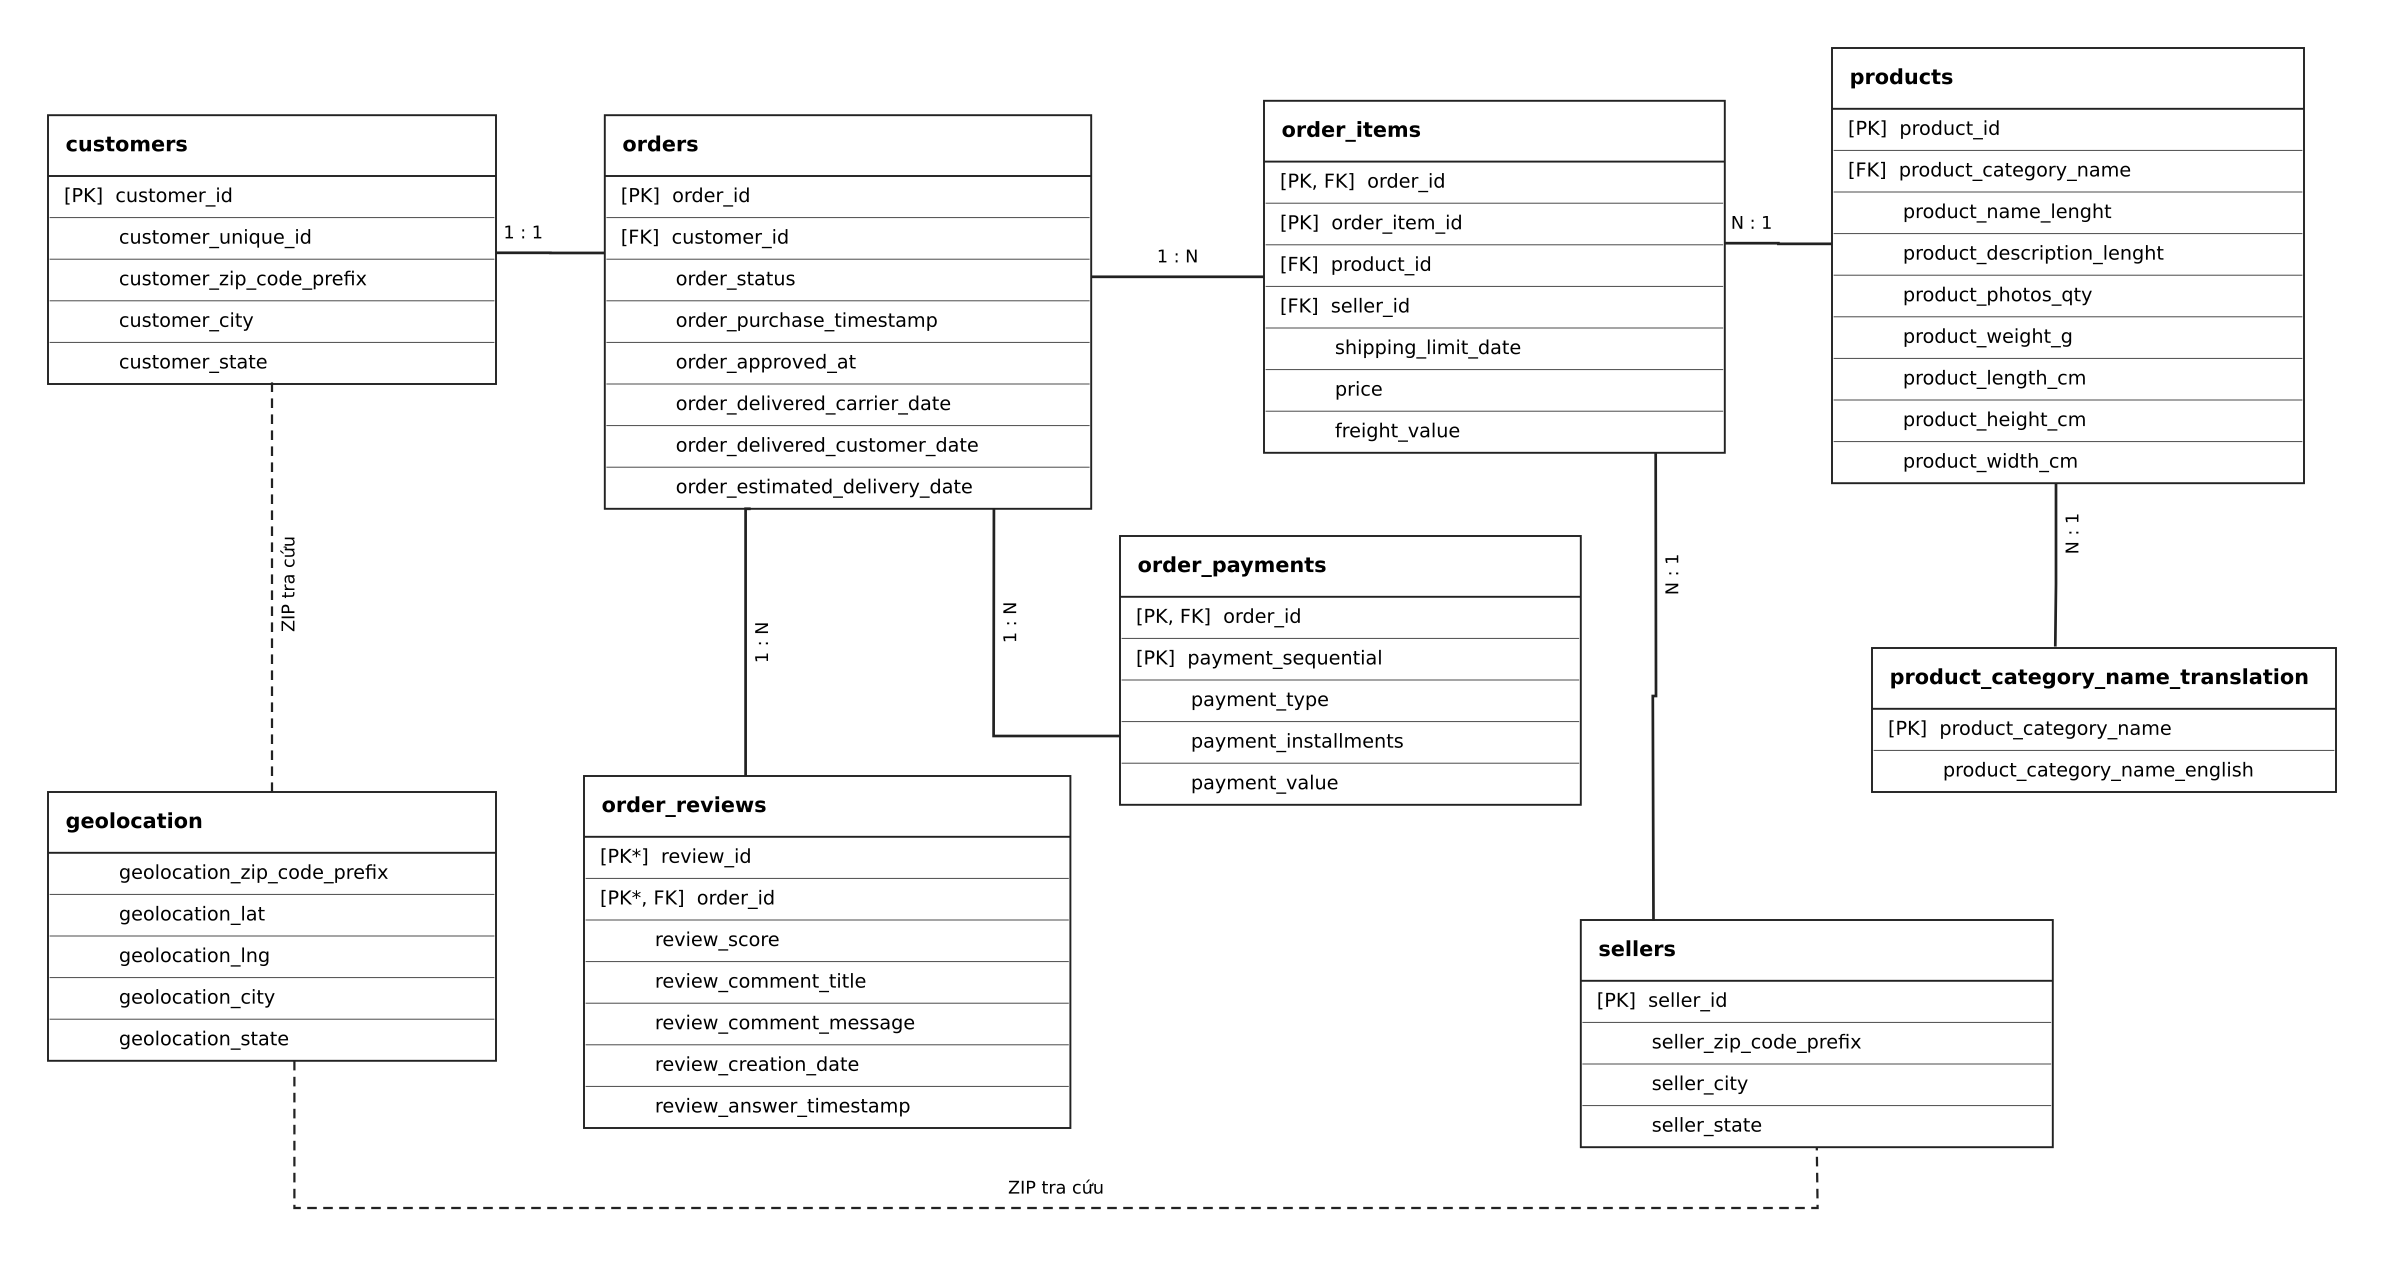

*Hình 3.1. Sơ đồ ERD Olist do Lam Linh thiết kế bằng draw.io.*

Ký hiệu PK chỉ khóa chính; FK chỉ trường liên kết; PK* ở bảng đánh giá là cặp khóa được kiểm tra trong dữ liệu. Quan hệ 1:N cho biết một bản ghi có thể liên quan đến nhiều bản ghi ở bảng khác. Liên kết ZIP là tra cứu địa lý, không phải khóa duy nhất của bảng geolocation gốc.


In [3]:
cardinality = pd.DataFrame([
 {'quan_he':'customers → orders','khoa':'customer_id','cap_du_lieu':'1:1 quan sát trong bộ dữ liệu',
  'so_khoa_con_lap':int(raw['orders']['customer_id'].duplicated().sum())},
 {'quan_he':'orders → items','khoa':'order_id','cap_du_lieu':'1:N', 'so_khoa_con_lap':int(raw['items']['order_id'].duplicated().sum())},
 {'quan_he':'orders → payments','khoa':'order_id','cap_du_lieu':'1:N','so_khoa_con_lap':int(raw['payments']['order_id'].duplicated().sum())},
 {'quan_he':'orders → reviews','khoa':'order_id','cap_du_lieu':'1:N','so_khoa_con_lap':int(raw['reviews']['order_id'].duplicated().sum())},
])
display(cardinality)
cardinality.to_csv(TABLES/'cardinality_audit.csv',index=False)


,quan_he,khoa,cap_du_lieu,so_khoa_con_lap
0,customers → orders,customer_id,1:1 quan sát trong bộ dữ liệu,0
1,orders → items,order_id,1:N,13984
2,orders → payments,order_id,1:N,4446
3,orders → reviews,order_id,1:N,551


Về nghiệp vụ, một người mua có thể phát sinh nhiều đơn hàng. Tuy nhiên, Olist cấp một `customer_id` riêng cho mỗi đơn. Vì vậy, quan hệ customers–orders theo `customer_id` trong dữ liệu đang xét là **1:1**, còn việc nhận diện người mua lặp phải dựa vào `customer_unique_id`. Sơ đồ biểu diễn quan hệ theo khóa customer_id của các bảng; quan hệ người mua–đơn hàng theo customer_unique_id vẫn là 1:N.

Khóa của items là cặp `order_id, order_item_id`; khóa của payments là `order_id, payment_sequential`. Với reviews, cặp `review_id, order_id` được kiểm tra thay vì ép riêng `review_id` phải duy nhất. Các bảng giao dịch phải được tổng hợp trước khi nối về cấp đơn hàng.

Geolocation có nhiều tọa độ cho cùng ZIP prefix nên được tổng hợp thành một dòng/ZIP trước khi tra cứu. Translation được dùng để kiểm tra tên danh mục, nhưng không phải danh mục nào cũng có bản dịch. Hai bảng này và reviews được xử lý riêng; chúng không tạo feature trong bộ baseline của nghiên cứu.


## 3.2. Tích hợp và làm sạch dữ liệu

Quy trình gồm chuẩn hóa chuỗi và kiểu dữ liệu, kiểm tra khóa, xử lý dòng trùng hoàn toàn, đánh dấu các giá trị bất thường, sau đó tổng hợp và kết nối các bảng. Dữ liệu thiếu được xử lý theo ý nghĩa từng trường: không tự điền ngày giao, không xóa đánh giá chỉ vì thiếu bình luận và không xem mã đơn lặp trong bảng items là lỗi.

Các cờ QA giữ lại dấu vết của những trường hợp bất thường. Những phép điền thiếu, mã hóa và chuẩn hóa có học từ dữ liệu được tách khỏi bước này để chỉ fit trên tập Train ở Chương 4.


### 3.2.1. Đơn hàng


In [4]:
orders = start_clean('orders')
require_key(orders, ['order_id'], 'orders')
orders['order_status'] = orders['order_status'].astype('string').str.lower()
valid_status = {'delivered', 'shipped', 'canceled', 'unavailable', 'invoiced', 'processing', 'created', 'approved'}
orders['qa_unknown_status'] = ~orders['order_status'].isin(valid_status)
parse_dates(orders, ['order_purchase_timestamp', 'order_approved_at',
                    'order_delivered_carrier_date', 'order_delivered_customer_date',
                    'order_estimated_delivery_date'], 'orders')
orders['qa_approved_before_purchase'] = orders['order_approved_at'] < orders['order_purchase_timestamp']
orders['qa_carrier_before_approved'] = orders['order_delivered_carrier_date'] < orders['order_approved_at']
orders['qa_delivery_before_carrier'] = orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']
orders['qa_delivery_before_approved'] = orders['order_delivered_customer_date'] < orders['order_approved_at']
orders['qa_delivery_before_purchase'] = orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']
orders['qa_estimate_before_purchase'] = orders['order_estimated_delivery_date'].dt.normalize() < orders['order_purchase_timestamp'].dt.normalize()
for c in orders.filter(like='qa_').columns:
    record('orders', c, orders[c].sum(), 'keep_flag_review_before_changing_cohort')
display(orders['order_status'].value_counts(dropna=False).rename('orders').to_frame())
display(orders.filter(like='qa_').sum().rename('flagged_rows').to_frame())


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,flagged_rows
qa_unknown_status,0
qa_approved_before_purchase,0
qa_carrier_before_approved,1359
qa_delivery_before_carrier,23
qa_delivery_before_approved,61
qa_delivery_before_purchase,0
qa_estimate_before_purchase,0


Nhận xét: Có 96.478/99.441 đơn ở trạng thái delivered. Không có trạng thái lạ, nhưng có 1.359 bản ghi bàn giao vận chuyển trước thời điểm duyệt, 23 bản ghi giao khách trước khi bàn giao vận chuyển và 61 bản ghi giao khách trước khi duyệt. Các nhóm này có thể trùng nhau nên không cộng thành tổng số đơn lỗi. Các cờ được giữ để kiểm tra độ nhạy của mẫu tại mục 3.3; không tự sửa các mốc thời gian gốc.


### 3.2.2. Items – sản phẩm trong đơn hàng
Kiểm tra khóa ghép, giá, phí vận chuyển và ngày giới hạn gửi hàng.


In [5]:
items = start_clean('items')
to_number(items, ['order_item_id', 'price', 'freight_value'], 'items')
require_key(items, ['order_id', 'order_item_id'], 'items')
parse_dates(items, ['shipping_limit_date'], 'items')
items['qa_invalid_item_number'] = items['order_item_id'].isna() | (items['order_item_id'] < 1) | (items['order_item_id'] % 1 != 0)
items['qa_nonpositive_price'] = items['price'].isna() | (items['price'] <= 0)
items['qa_negative_freight'] = items['freight_value'] < 0
items['qa_missing_product_or_seller'] = items[['product_id', 'seller_id']].isna().any(axis=1)
for c in items.filter(like='qa_').columns:
    record('items', c, items[c].sum(), 'keep_flag_for_review')
display(items[['price', 'freight_value']].describe(percentiles=[.5,.95,.99]))
print('Item có phí vận chuyển bằng 0, giữ lại:', int(items['freight_value'].eq(0).sum()))


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
50%,74.990000,16.260000
95%,349.900000,45.120000
99%,890.000000,84.520000
max,6735.000000,409.680000


Item có phí vận chuyển bằng 0, giữ lại: 383


Nhận xét: Giá sản phẩm có trung vị 74,99 BRL và trung bình 120,65 BRL, cho thấy có những mặt hàng giá cao kéo trung bình lên. Có 383 dòng phí vận chuyển bằng 0; các dòng này được giữ vì chưa có căn cứ xem phí 0 là sai. Không phát hiện giá âm trong thống kê hiển thị.


### 3.2.3. Customers – khách hàng
Kiểm tra khóa khách hàng, chuẩn hóa mã ZIP, tên thành phố và mã bang.


In [6]:
customers = start_clean('customers')
require_key(customers, ['customer_id'], 'customers')
customers = normalize_location(customers, 'customer', 'customers')
print('Số bản ghi customer:', len(customers))
print('Số khách phân biệt theo customer_unique_id:', customers['customer_unique_id'].nunique())
display(customers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0


Số bản ghi customer: 99441
Số khách phân biệt theo customer_unique_id: 96096


Nhận xét: Bảng có 99.441 bản ghi khách hàng, tương ứng 96.096 mã customer_unique_id khác nhau. Một người có thể mua nhiều đơn, nên không xóa các mã khách hàng lặp theo customer_unique_id. Không phát hiện ZIP hoặc mã bang không hợp lệ theo quy tắc đang kiểm tra.


### 3.2.4. Sellers – người bán
Chuẩn hóa thông tin địa lý và kiểm tra seller_id.


In [7]:
sellers = start_clean('sellers')
require_key(sellers, ['seller_id'], 'sellers')
sellers = normalize_location(sellers, 'seller', 'sellers')
print('Số người bán:', len(sellers))
display(sellers[['qa_invalid_zip','qa_invalid_state']].sum().rename('flagged_rows').to_frame())


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0


Số người bán: 3095


Nhận xét: Có 3.095 người bán. Không ghi nhận mã ZIP hoặc mã bang không hợp lệ theo phép kiểm tra hiện tại, nên không có bản ghi nào bị loại ở bước này.


### 3.2.5. Products – sản phẩm
Kiểm tra các thuộc tính mô tả sản phẩm; giữ nguyên cột gốc và đánh dấu các giá trị bất thường.


In [8]:
products = start_clean('products')
require_key(products, ['product_id'], 'products')
product_numeric = ['product_name_lenght','product_description_lenght','product_photos_qty',
                   'product_weight_g','product_length_cm','product_height_cm','product_width_cm']
to_number(products, product_numeric, 'products')
products['qa_missing_category'] = products['product_category_name'].isna()
for c in ['product_weight_g','product_length_cm','product_height_cm','product_width_cm']:
    products[c + '_raw'] = products[c]
    invalid = products[c].notna() & (products[c] <= 0)
    products['qa_nonpositive_' + c] = invalid
    products.loc[invalid, c] = np.nan
    record('products', 'nonpositive:' + c, invalid.sum(), 'set_NA_keep_original_raw_column')
for c in ['product_name_lenght','product_description_lenght','product_photos_qty']:
    products['qa_invalid_' + c] = products[c].notna() & ((products[c] < 0) | (products[c] % 1 != 0))
display(products[['product_category_name'] + product_numeric].isna().sum().rename('missing_after').to_frame())
print('Trọng lượng 0/âm đã chuyển thành thiếu:', int(products['qa_nonpositive_product_weight_g'].sum()))


,missing_after
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,6
product_length_cm,2
product_height_cm,2
product_width_cm,2


Trọng lượng 0/âm đã chuyển thành thiếu: 4


Nhận xét: Có 610 sản phẩm thiếu danh mục và đồng thời thiếu các thông tin độ dài tên, mô tả, số ảnh. Trọng lượng ban đầu thiếu 2 dòng; thêm 4 dòng có trọng lượng bằng 0 hoặc âm được chuyển thành thiếu, nên sau xử lý có 6 dòng thiếu trọng lượng. Không tự điền giá trị vì chưa có cơ sở xác định trọng lượng thực tế.


### 3.2.6. Payments – thanh toán
Kiểm tra thứ tự thanh toán, hình thức thanh toán, số kỳ và giá trị tiền.


In [9]:
payments = start_clean('payments')
to_number(payments, ['payment_sequential','payment_installments','payment_value'], 'payments')
require_key(payments, ['order_id','payment_sequential'], 'payments')
payments['payment_type'] = payments['payment_type'].astype('string').str.lower()
payments['qa_unknown_payment_type'] = ~payments['payment_type'].isin(['credit_card','boleto','voucher','debit_card','not_defined'])
payments['qa_not_defined'] = payments['payment_type'].eq('not_defined').fillna(False)
payments['qa_zero_value'] = payments['payment_value'].eq(0)
payments['qa_zero_installments'] = payments['payment_installments'].eq(0)
payments['qa_invalid_value'] = payments['payment_value'].isna() | payments['payment_value'].lt(0)
payments['qa_invalid_installments'] = payments['payment_installments'].isna() | payments['payment_installments'].lt(0) | (payments['payment_installments'] % 1 != 0)
payments['qa_invalid_sequential'] = payments['payment_sequential'].isna() | payments['payment_sequential'].lt(1) | (payments['payment_sequential'] % 1 != 0)
for c in payments.filter(like='qa_').columns:
    record('payments', c, payments[c].sum(), 'keep_flag_for_review')
display(payments.filter(like='qa_').sum().rename('flagged_rows').to_frame())
display(payments['payment_type'].value_counts(dropna=False).to_frame('records'))


,flagged_rows
qa_unknown_payment_type,0
qa_not_defined,3
qa_zero_value,9
qa_zero_installments,2
qa_invalid_value,0
qa_invalid_installments,0
qa_invalid_sequential,0


,records
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


Nhận xét: Thanh toán bằng credit_card chiếm số lượng nhiều nhất (76.795 bản ghi). Có 3 bản ghi not_defined, 9 bản ghi số tiền bằng 0 và 2 bản ghi số kỳ trả góp bằng 0. Các trường hợp này được giữ kèm cờ QA vì chưa đủ căn cứ để thay thế hoặc loại bỏ giá trị.


### 3.2.7. Reviews – đánh giá đơn hàng
Kiểm tra điểm đánh giá, thời gian tạo/trả lời và nội dung bình luận.


In [10]:
reviews = start_clean('reviews')
require_key(reviews, ['review_id','order_id'], 'reviews')
to_number(reviews, ['review_score'], 'reviews')
parse_dates(reviews, ['review_creation_date','review_answer_timestamp'], 'reviews')
reviews['qa_invalid_review_score'] = reviews['review_score'].isna() | ~reviews['review_score'].between(1,5) | (reviews['review_score'] % 1 != 0)
reviews['qa_answer_before_creation'] = reviews['review_answer_timestamp'] < reviews['review_creation_date']
reviews['has_comment_title'] = reviews['review_comment_title'].notna()
reviews['has_comment_message'] = reviews['review_comment_message'].notna()
for c in reviews.filter(like='qa_').columns:
    record('reviews', c, reviews[c].sum(), 'keep_flag_for_review')
print('Số dòng review_id lặp vượt lần đầu:', int(reviews['review_id'].duplicated().sum()))
print('Số dòng order_id lặp vượt lần đầu:', int(reviews['order_id'].duplicated().sum()))
display(reviews[['review_comment_title','review_comment_message']].isna().sum().to_frame('missing'))
display(reviews.filter(like='qa_').sum().to_frame('flagged_rows'))


,missing
review_comment_title,87658
review_comment_message,58274


,flagged_rows
qa_invalid_review_score,0
qa_answer_before_creation,0


Số dòng review_id lặp vượt lần đầu: 814
Số dòng order_id lặp vượt lần đầu: 551


Nhận xét: Sau khi chuẩn hóa chuỗi rỗng, có 87.658 tiêu đề và 58.274 nội dung bình luận bị thiếu; số này tăng nhẹ so với dữ liệu gốc do một số ô chỉ chứa khoảng trắng. Không thấy điểm đánh giá ngoài khoảng 1–5 hoặc thời gian trả lời sớm hơn ngày tạo. review_id có 814 lần lặp vượt lần xuất hiện đầu, order_id có 551 lần lặp; cần hiểu cấu trúc đánh giá, không xóa chỉ vì một trong hai mã lặp.


### 3.2.8. Geolocation – dữ liệu địa lý
Bỏ dòng trùng hoàn toàn, kiểm tra tọa độ và lập bảng tọa độ đại diện cho từng mã ZIP.


In [11]:
geolocation = start_clean('geolocation')
geolocation = normalize_location(geolocation, 'geolocation', 'geolocation')
to_number(geolocation, ['geolocation_lat','geolocation_lng'], 'geolocation')
geolocation['qa_invalid_world_coordinate'] = (~geolocation['geolocation_lat'].between(-90,90)
                                             | ~geolocation['geolocation_lng'].between(-180,180))
geolocation['qa_outside_brazil_screen'] = (~geolocation['geolocation_lat'].between(-34,6)
                                          | ~geolocation['geolocation_lng'].between(-74,-34))
for c in ['qa_invalid_world_coordinate','qa_outside_brazil_screen']:
    record('geolocation', c, geolocation[c].sum(), 'retain_in_clean_exclude_from_zip_representative')
usable_geo = geolocation.loc[~geolocation['qa_invalid_world_coordinate']
                            & ~geolocation['qa_outside_brazil_screen']
                            & ~geolocation['qa_invalid_zip']]
geo_by_zip = usable_geo.groupby('geolocation_zip_code_prefix', as_index=False).agg(
    latitude=('geolocation_lat','median'), longitude=('geolocation_lng','median'),
    coordinate_records=('geolocation_lat','size'))
assert geo_by_zip['geolocation_zip_code_prefix'].is_unique
geo_by_zip.to_csv(PROCESSED / 'geolocation_by_zip.csv', index=False)
print('Dòng gốc:', len(raw['geolocation']), '| sau bỏ trùng:', len(geolocation))
display(geolocation.filter(like='qa_').sum().to_frame('flagged_rows'))
print('ZIP có tọa độ đại diện hợp lệ:', len(geo_by_zip))


,flagged_rows
qa_invalid_zip,0
qa_invalid_state,0
qa_invalid_world_coordinate,0
qa_outside_brazil_screen,33


Dòng gốc: 1000163 | sau bỏ trùng: 738332
ZIP có tọa độ đại diện hợp lệ: 19010


Nhận xét: Bảng giảm từ 1.000.163 xuống 738.332 dòng sau khi bỏ 261.831 dòng trùng hoàn toàn. Có 33 tọa độ nằm ngoài khoảng sàng lọc rộng đang dùng cho Brazil; các dòng vẫn được giữ trong bảng sạch và không đưa vào tính tọa độ ZIP đại diện. Sau lọc, tạo được 19.010 mã ZIP có tọa độ đại diện. Khoảng sàng lọc chỉ để kiểm tra nhanh, không phải ranh giới hành chính chính xác.


### 3.2.9. Translation – dịch danh mục sản phẩm
Đối chiếu danh mục sản phẩm với bảng dịch sang tiếng Anh.


In [12]:
translation = start_clean('translation')
for c in ['product_category_name','product_category_name_english']:
    translation[c] = translation[c].astype('string').str.lower()
require_key(translation, ['product_category_name'], 'translation')
translation['qa_missing_english'] = translation['product_category_name_english'].isna()
untranslated = (products.loc[products['product_category_name'].notna()
                 & ~products['product_category_name'].isin(translation['product_category_name']),
                 'product_category_name'].value_counts().rename_axis('category').reset_index(name='products'))
untranslated.to_csv(TABLES / 'untranslated_categories.csv', index=False)
display(untranslated)
print('Bản dịch thiếu tiếng Anh:', int(translation['qa_missing_english'].sum()))


,category,products
0,portateis_cozinha_e_preparadores_de_alimentos,10
1,pc_gamer,3


Bản dịch thiếu tiếng Anh: 0


Nhận xét: Không có bản dịch thiếu tiếng Anh trong bảng translation, nhưng có 2 danh mục sản phẩm không tìm thấy bản dịch: portateis_cozinha_e_preparadores_de_alimentos (10 sản phẩm) và pc_gamer (3 sản phẩm). Giữ lại tên danh mục gốc, không tự tạo bản dịch.


### 3.2.10. Đối soát và lưu 9 bảng sạch
Kiểm tra khóa ngoại giữa các bảng và số dòng trước/sau làm sạch.


In [13]:
clean = dict(orders=orders, items=items, customers=customers, sellers=sellers,
             products=products, payments=payments, reviews=reviews,
             geolocation=geolocation, translation=translation)
relations = [
    ('orders','customer_id','customers','customer_id'),
    ('items','order_id','orders','order_id'),
    ('items','product_id','products','product_id'),
    ('items','seller_id','sellers','seller_id'),
    ('payments','order_id','orders','order_id'),
    ('reviews','order_id','orders','order_id'),
]
fk_rows=[]
for child, ck, parent, pk in relations:
    s=clean[child][ck]
    fk_rows.append({'child':child, 'key':ck, 'parent':parent,
                    'missing_key':int(s.isna().sum()),
                    'orphan_rows':int((s.notna() & ~s.isin(clean[parent][pk])).sum())})
fk_report=pd.DataFrame(fk_rows)
fk_report.to_csv(TABLES/'foreign_key_audit.csv',index=False)
display(fk_report)
assert fk_report[['missing_key','orphan_rows']].to_numpy().sum() == 0, 'Có khóa ngoại chưa giải quyết; xem báo cáo.'
summary=[]
for name,d in clean.items():
    original_cols=raw[name].columns
    filename=Path(NAMES[name]).stem + '_clean.csv'
    d.to_csv(CLEAN_DIR/filename,index=False)
    summary.append({'table':name,'rows_before':len(raw[name]),'rows_after':len(d),
                    'removed_rows':len(raw[name])-len(d),
                    'missing_before':int(raw[name].isna().sum().sum()),
                    'missing_after_original_columns':int(d[original_cols].isna().sum().sum()),
                    'qa_flag_columns':len(d.filter(like='qa_').columns),
                    'rows_with_any_qa_flag':int(d.filter(like='qa_').fillna(False).any(axis=1).sum())})
clean_summary=pd.DataFrame(summary)
clean_summary.to_csv(TABLES/'cleaning_summary.csv',index=False)
pd.DataFrame(LOG).to_csv(TABLES/'cleaning_log.csv',index=False)
display(clean_summary)
assert len(clean)==9
print('Đã xuất 9 bảng sạch tại:', CLEAN_DIR.relative_to(ROOT))


,child,key,parent,missing_key,orphan_rows
0,orders,customer_id,customers,0,0
1,items,order_id,orders,0,0
2,items,product_id,products,0,0
3,items,seller_id,sellers,0,0
4,payments,order_id,orders,0,0
5,reviews,order_id,orders,0,0


,table,rows_before,rows_after,removed_rows,missing_before,missing_after_original_columns,qa_flag_columns,rows_with_any_qa_flag
0,orders,99441,99441,0,4908,4908,7,1382
1,items,112650,112650,0,0,0,4,0
2,customers,99441,99441,0,0,0,2,0
3,sellers,3095,3095,0,0,0,2,0
4,products,32951,32951,0,2448,2452,8,614
5,payments,103886,103886,0,0,0,7,11
6,reviews,99224,99224,0,145903,145932,2,0
7,geolocation,1000163,738332,261831,0,0,4,33
8,translation,71,71,0,0,0,1,0


Đã xuất 9 bảng sạch tại: data/processed/cleaned


Nhận xét: Cả 6 quan hệ khóa ngoại được kiểm tra đều không có khóa thiếu hoặc bản ghi mồ côi. Trong 9 bảng, chỉ geolocation giảm số dòng do bỏ trùng; các bảng khác giữ nguyên số dòng. Số ô thiếu ở products và reviews tăng nhẹ vì chuẩn hóa giá trị không hợp lệ hoặc chuỗi trắng thành thiếu, không có nghĩa dữ liệu bị mất ngoài kiểm soát.


### 3.2.11. Tổng hợp kết quả làm sạch
`clean_summary` tổng hợp số dòng trước/sau xử lý, số ô thiếu trên các cột gốc và số dòng có ít nhất một cờ QA. Cách đếm này không cộng trùng một dòng chứa nhiều loại bất thường.

Geolocation giảm từ **1.000.163 xuống 738.332 dòng** do loại 261.831 bản ghi trùng hoàn toàn. Tám bảng còn lại giữ nguyên số dòng. Số ô thiếu của products tăng từ **2.448 lên 2.452**, do bốn giá trị trọng lượng không hợp lệ được chuyển thành NaN. Reviews tăng từ **145.903 lên 145.932 ô thiếu** sau khi chuẩn hóa chuỗi chỉ chứa khoảng trắng.

Như vậy, mục tiêu làm sạch là thống nhất định dạng, kiểm soát khóa và ghi nhận rõ các vấn đề của dữ liệu. Những ô thiếu có ý nghĩa nghiệp vụ vẫn được giữ lại; không thay chúng bằng số 0 chỉ để làm giảm tỷ lệ thiếu.


### 3.2.12. Tích hợp về cấp đơn hàng
Items được nối với products và sellers, sau đó tổng hợp số item, số sản phẩm, số người bán, giá, phí vận chuyển và các thuộc tính mô tả theo `order_id`. Payments được tổng hợp riêng trước khi nối vào orders. Các phép merge có ràng buộc cardinality để phát hiện việc nhân dòng.

Reviews phục vụ phân tích hậu nghiệm nên không ghép vào đầu vào dự báo. Geolocation và translation được xuất thành bảng hỗ trợ sau làm sạch.


In [14]:
def summarize_distinct(s):
    values=sorted(s.dropna().astype(str).unique())
    return values[0] if len(values)==1 else ('MULTI' if len(values)>1 else 'UNKNOWN')

enriched=(items.merge(products[['product_id','product_category_name','product_weight_g']],
                       on='product_id',how='left',validate='many_to_one')
          .merge(sellers[['seller_id','seller_state']],on='seller_id',how='left',validate='many_to_one'))
item_agg=enriched.groupby('order_id',as_index=False).agg(
    item_count=('order_item_id','size'), product_count=('product_id','nunique'),
    seller_count=('seller_id','nunique'), total_price=('price',lambda s:s.sum(min_count=1)),
    total_freight=('freight_value',lambda s:s.sum(min_count=1)),
    price_known_items=('price','count'), freight_known_items=('freight_value','count'),
    avg_weight_g=('product_weight_g','mean'), weight_known_items=('product_weight_g','count'),
    seller_region=('seller_state',summarize_distinct),
    product_category=('product_category_name',summarize_distinct))
payment_agg=payments.groupby('order_id',as_index=False).agg(
    total_payment=('payment_value',lambda s:s.sum(min_count=1)),
    payment_records=('payment_sequential','size'))
base=(orders.merge(customers[['customer_id','customer_state']],on='customer_id',how='left',validate='many_to_one')
      .merge(item_agg,on='order_id',how='left',validate='one_to_one')
      .merge(payment_agg,on='order_id',how='left',validate='one_to_one'))
assert base['order_id'].is_unique and base['order_id'].notna().all()
assert len(base)==len(orders)
join_audit=pd.DataFrame([
    {'metric':'orders_before_join','count':len(orders)},
    {'metric':'orders_after_join','count':len(base)},
    {'metric':'orders_without_items','count':int(base['item_count'].isna().sum())},
    {'metric':'orders_without_payment','count':int(base['payment_records'].isna().sum())},
    {'metric':'orders_with_multiple_sellers','count':int(base['seller_count'].gt(1).sum())},
])
join_audit.to_csv(TABLES/'join_audit.csv',index=False)
display(join_audit)
# Bảng nối đơn-người bán dành cho EDA riêng, không đưa vào mô hình cấp đơn.
order_seller=enriched[['order_id','seller_id']].drop_duplicates()

reconciliation = pd.DataFrame([
 {'metric':'total_price','before':items['price'].sum(min_count=1),'after':base['total_price'].sum(min_count=1)},
 {'metric':'total_freight','before':items['freight_value'].sum(min_count=1),'after':base['total_freight'].sum(min_count=1)},
 {'metric':'total_payment','before':payments['payment_value'].sum(min_count=1),'after':base['total_payment'].sum(min_count=1)},
 {'metric':'item_count','before':len(items),'after':base['item_count'].sum(min_count=1)}])
reconciliation['difference']=reconciliation['after']-reconciliation['before']
assert np.allclose(reconciliation['before'],reconciliation['after'],rtol=0,atol=1e-6)
reconciliation.to_csv(TABLES/'aggregation_reconciliation.csv',index=False)
display(reconciliation)


,metric,count
0,orders_before_join,99441
1,orders_after_join,99441
2,orders_without_items,775
3,orders_without_payment,1
4,orders_with_multiple_sellers,1278


,metric,before,after,difference
0,total_price,13591643.70,13591643.70,0.0
1,total_freight,2251909.54,2251909.54,0.0
2,total_payment,16008872.12,16008872.12,0.0
3,item_count,112650.00,112650.00,0.0


Nhận xét: Sau khi nối, dữ liệu vẫn có 99.441 đơn, không phát sinh thêm dòng. Có 775 đơn không có chi tiết sản phẩm, 1 đơn không có thanh toán và 1.278 đơn có nhiều người bán. Các trường hợp này được ghi nhận để tránh làm sai số lượng đơn khi phân tích.

`seller_region=MULTI` nghĩa là các item thuộc **nhiều bang người bán khác nhau**. Nếu nhiều seller cùng ở SP thì vùng tổng hợp vẫn là SP. Tương tự, `product_category=MULTI` là nhiều danh mục, không phải nhiều sản phẩm. Tổng tiền sau join được đối chiếu với bảng giao dịch để phát hiện nhân dòng hoặc mất dữ liệu.


## 3.3. Nhãn và chọn mẫu


### 3.3.1. Quy tắc tạo nhãn
Chỉ gán nhãn cho đơn ở trạng thái `delivered`, có ngày phê duyệt, ngày giao thực tế và ngày giao dự kiến hợp lệ. Sau khi quy đổi timestamp về ngày lịch:

$$
\mathrm{is\_late}=\begin{cases}
1,&\text{ngày giao thực tế > ngày giao dự kiến}\\
0,&\text{ngày giao thực tế ≤ ngày giao dự kiến}
\end{cases}
$$

Đơn giao vào bất kỳ giờ nào trong đúng ngày dự kiến vẫn được xem là đúng hạn. Đơn hủy, chưa giao thành công hoặc thiếu ngày bắt buộc được giữ ngoài tập có nhãn; không gán chúng thành lớp 0.


In [15]:
conditions=[
    ('not_delivered',base['order_status'].eq('delivered')),
    ('missing_approved_at',base['order_approved_at'].notna()),
    ('missing_actual_delivery',base['order_delivered_customer_date'].notna()),
    ('missing_estimated_delivery',base['order_estimated_delivery_date'].notna()),
]
remaining=pd.Series(True,index=base.index)
exclusion=[]
for reason, valid in conditions:
    valid=valid.fillna(False)
    removed=remaining & ~valid
    exclusion.append({'reason':reason,'excluded_orders':int(removed.sum())})
    remaining &= valid
base['is_late']=pd.Series(pd.NA,index=base.index,dtype='Int64')
base.loc[remaining,'is_late']=(
    base.loc[remaining,'order_delivered_customer_date'].dt.normalize()
    > base.loc[remaining,'order_estimated_delivery_date'].dt.normalize()).astype('int64')
model_data=base.loc[remaining].copy()
model_data['is_late']=model_data['is_late'].astype(int)
exclusion_table=pd.DataFrame(exclusion)
assert int(exclusion_table['excluded_orders'].sum())+len(model_data)==len(base)
assert model_data['order_id'].is_unique and model_data['is_late'].isin([0,1]).all()
label_audit=pd.DataFrame([{'all_orders':len(base),'labeled_orders':len(model_data),
                         'unlabeled_orders':len(base)-len(model_data),
                         'late_orders':int(model_data['is_late'].sum()),
                         'late_rate':model_data['is_late'].mean()}])
exclusion_table.to_csv(TABLES/'label_exclusions.csv',index=False)
label_audit.to_csv(TABLES/'label_audit.csv',index=False)
display(exclusion_table)
display(label_audit)
# Kiểm tra độ nhạy mô tả, CHƯA thay đổi tập mô hình chính.
time_flags=['qa_approved_before_purchase','qa_carrier_before_approved',
            'qa_delivery_before_carrier','qa_delivery_before_approved',
            'qa_delivery_before_purchase','qa_estimate_before_purchase']
flagged=model_data[time_flags].any(axis=1)
sensitivity=pd.DataFrame([
    {'cohort':'main_contract','orders':len(model_data),'late_rate':model_data['is_late'].mean()},
    {'cohort':'exclude_any_chronology_flag_for_review','orders':int((~flagged).sum()),
     'late_rate':model_data.loc[~flagged,'is_late'].mean()}
])
sensitivity.to_csv(TABLES/'chronology_sensitivity.csv',index=False)
display(sensitivity)


,reason,excluded_orders
0,not_delivered,2963
1,missing_approved_at,14
2,missing_actual_delivery,8
3,missing_estimated_delivery,0


,all_orders,labeled_orders,unlabeled_orders,late_orders,late_rate
0,99441,96456,2985,6534,0.067741


,cohort,orders,late_rate
0,main_contract,96456,0.067741
1,exclude_any_chronology_flag_for_review,95083,0.068466


Nhận xét: Từ 99.441 đơn, loại 2.963 đơn chưa ở trạng thái delivered, 14 đơn thiếu ngày duyệt và 8 đơn thiếu ngày giao thực tế (theo thứ tự lọc). Còn 96.456 đơn có nhãn, trong đó 6.534 đơn giao trễ, chiếm 6,77%. Nếu tạm loại các đơn có cờ bất thường thời gian, mẫu còn 95.083 đơn với tỷ lệ trễ 6,85%; đây chỉ là kiểm tra độ nhạy, chưa thay đổi tập dữ liệu chính.


### 3.3.2. Luồng chọn mẫu và kiểm tra độ nhạy


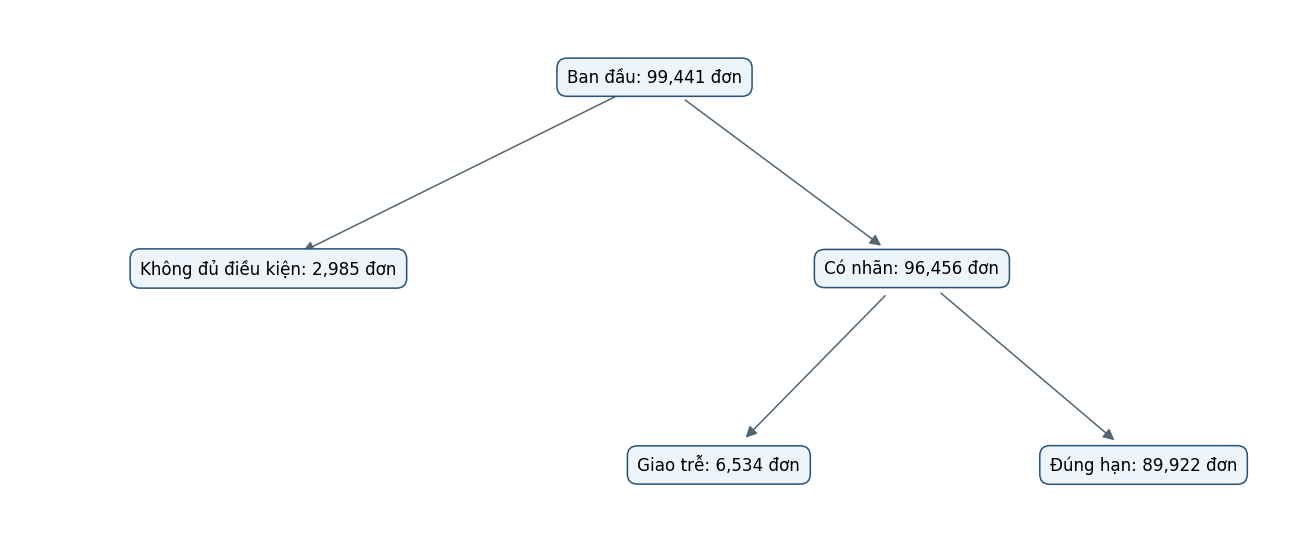

Tập phân tích gồm 96,456 đơn, trong đó 6,534 đơn giao trễ (6.77%). Các lý do loại được áp dụng tuần tự nên không đếm trùng một đơn. Tập này chỉ phản ánh đơn delivered đủ dữ liệu, không đại diện cho đơn hủy hoặc đang giao. Mẫu chính giữ các bản ghi có cờ thời gian để bảo toàn quy tắc chọn mẫu; không sửa hoặc suy đoán lại timestamp. Khi loại toàn bộ đơn có ít nhất một cờ thời gian, số mẫu và tỷ lệ trễ thay đổi như bảng kiểm tra độ nhạy. Đây là giới hạn chất lượng timestamp của nghiên cứu, đặc biệt với các đơn có ngày giao trước thời điểm duyệt. Bảng độ nhạy chỉ mô tả ảnh hưởng đến tỷ lệ trễ, không chứng minh những bản ghi này không ảnh hưởng đến kết quả mô hình. Ở bước chia tập theo thời gian, ngày giao thực tế được dùng kiểm tra nhãn đã hình thành trước cutoff và không được đưa vào X.

In [16]:
n_all=len(base); n_labeled=len(model_data); n_late=int(model_data['is_late'].sum())
labels=[f'Ban đầu: {n_all:,} đơn',f'Không đủ điều kiện: {n_all-n_labeled:,} đơn',
        f'Có nhãn: {n_labeled:,} đơn',f'Giao trễ: {n_late:,} đơn',f'Đúng hạn: {n_labeled-n_late:,} đơn']
fig,ax=plt.subplots(figsize=(12,5));ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
pos=[(.5,.87),(.2,.5),(.7,.5),(.55,.12),(.88,.12)]
for (x,y),txt in zip(pos,labels):
 ax.text(x,y,txt,ha='center',va='center',fontsize=11,bbox=dict(boxstyle='round,pad=.6',fc='#edf4fa',ec='#285378'))
for a,b in [(0,1),(0,2),(2,3),(2,4)]:
 ax.add_patch(FancyArrowPatch(pos[a],pos[b],arrowstyle='-|>',shrinkA=25,shrinkB=25,mutation_scale=15,color='#526675'))
fig.tight_layout();fig.savefig(FIGURES/'ch03_label_flow.png',bbox_inches='tight');plt.show()
label_text=(f'Tập phân tích gồm {n_labeled:,} đơn, trong đó {n_late:,} đơn giao trễ ({n_late/n_labeled:.2%}). '
 'Các lý do loại được áp dụng tuần tự nên không đếm trùng một đơn. Tập này chỉ phản ánh đơn delivered đủ dữ liệu, không đại diện cho đơn hủy hoặc đang giao. '
 'Mẫu chính giữ các bản ghi có cờ thời gian để bảo toàn quy tắc chọn mẫu; không sửa hoặc suy đoán lại timestamp. '
 'Khi loại toàn bộ đơn có ít nhất một cờ thời gian, số mẫu và tỷ lệ trễ thay đổi như bảng kiểm tra độ nhạy. '
 'Đây là giới hạn chất lượng timestamp của nghiên cứu, đặc biệt với các đơn có ngày giao trước thời điểm duyệt. '
 'Bảng độ nhạy chỉ mô tả ảnh hưởng đến tỷ lệ trễ, không chứng minh những bản ghi này không ảnh hưởng đến kết quả mô hình. '
 'Ở bước chia tập theo thời gian, ngày giao thực tế được dùng kiểm tra nhãn đã hình thành trước cutoff và không được đưa vào X.')
explain('label',label_text)


## 3.4. Phân tích khám phá dữ liệu
EDA được thực hiện trên tập 96.456 đơn delivered có nhãn. Mỗi tỷ lệ được trình bày kèm số đơn của nhóm để tránh diễn giải quá mức các nhóm nhỏ. Các kết quả sau mô tả dữ liệu lịch sử, không chứng minh quan hệ nhân quả.

Phần này sử dụng toàn bộ tập có nhãn để mô tả. Do đó, lựa chọn mô hình, biến học từ dữ liệu và ngưỡng phân loại ở Chương 4 phải dựa trên Train/Validation, không dùng kết quả của vùng thời gian Test để tinh chỉnh.


In [17]:
model_data['purchase_month']=model_data['order_purchase_timestamp'].dt.to_period('M').astype('string')
# Các bin cố định phục vụ mô tả, không học từ Test.
model_data['order_value_group']=pd.cut(model_data['total_price'],[-np.inf,50,100,200,500,np.inf],
                                      labels=['<=50','50-100','100-200','200-500','>500'])
model_data['weight_group']=pd.cut(model_data['avg_weight_g'],[-np.inf,500,1000,5000,np.inf],
                                 labels=['<=500g','500-1000g','1000-5000g','>5000g'])
def late_table(d,group):
    return d.groupby(group,dropna=False,observed=True).agg(
        orders=('order_id','nunique'),late_orders=('is_late','sum'),
        late_rate=('is_late','mean')).reset_index()
eda={}
for group in ['purchase_month','customer_state','seller_region','product_category','order_value_group','weight_group']:
    eda[group]=late_table(model_data,group)
    eda[group].to_csv(TABLES/f'eda_{group}.csv',index=False)
seller_detail=order_seller.merge(model_data[['order_id','is_late']],on='order_id',how='inner',validate='many_to_one')
eda_seller=late_table(seller_detail,'seller_id')
eda_seller.to_csv(TABLES/'eda_seller_id.csv',index=False)
print('Theo seller_id: mỗi đơn được tính tối đa một lần trong từng seller; đơn nhiều seller có thể xuất hiện ở nhiều nhóm.')
print('Vì vậy không cộng số đơn giữa các seller để suy ra tổng đơn toàn bộ.')
display(eda['customer_state'].sort_values('orders',ascending=False).head(10))
display(eda['product_category'].sort_values('orders',ascending=False).head(10))
display(eda['order_value_group'])

overview=model_data[['total_price','total_freight','item_count','avg_weight_g']].describe(percentiles=[.5,.95,.99]).round(2)
overview.to_csv(TABLES/'eda_numeric_overview.csv')
display(overview)


,customer_state,orders,late_orders,late_rate
25,SP,40489,1820,0.044950
18,RJ,12348,1495,0.121072
10,MG,11351,519,0.045723
22,RS,5342,325,0.060839
17,PR,4923,199,0.040423
23,SC,3546,291,0.082064
4,BA,3256,396,0.121622
6,DF,2080,118,0.056731
7,ES,1995,214,0.107268
8,GO,1957,128,0.065406


,product_category,orders,late_orders,late_rate
15,cama_mesa_banho,9074,684,0.075380
13,beleza_saude,8578,648,0.075542
34,esporte_lazer,7460,493,0.066086
46,informatica_acessorios,6479,417,0.064362
56,moveis_decoracao,6102,446,0.073091
74,utilidades_domesticas,5641,307,0.054423
68,relogios_presentes,5453,406,0.074454
72,telefonia,4065,291,0.071587
10,automotivo,3774,278,0.073662
14,brinquedos,3753,241,0.064215


,order_value_group,orders,late_orders,late_rate
0,<=50,29040,1750,0.060262
1,50-100,27601,1838,0.066592
2,100-200,25280,1801,0.071242
3,200-500,11058,864,0.078133
4,>500,3477,281,0.080817


,total_price,total_freight,item_count,avg_weight_g
count,96456.00,96456.00,96456.00,96434.00
mean,137.04,22.79,1.14,2098.29
std,209.06,21.56,0.54,3744.86
min,0.85,0.00,1.00,2.00
50%,86.50,17.17,1.00,700.00
95%,399.00,54.78,2.00,9750.00
99%,990.00,104.25,3.00,18225.00
max,13440.00,1794.96,21.00,40425.00


Theo seller_id: mỗi đơn được tính tối đa một lần trong từng seller; đơn nhiều seller có thể xuất hiện ở nhiều nhóm.
Vì vậy không cộng số đơn giữa các seller để suy ra tổng đơn toàn bộ.


### 3.4.1. Phân bố số đơn và tỷ lệ trễ theo tháng


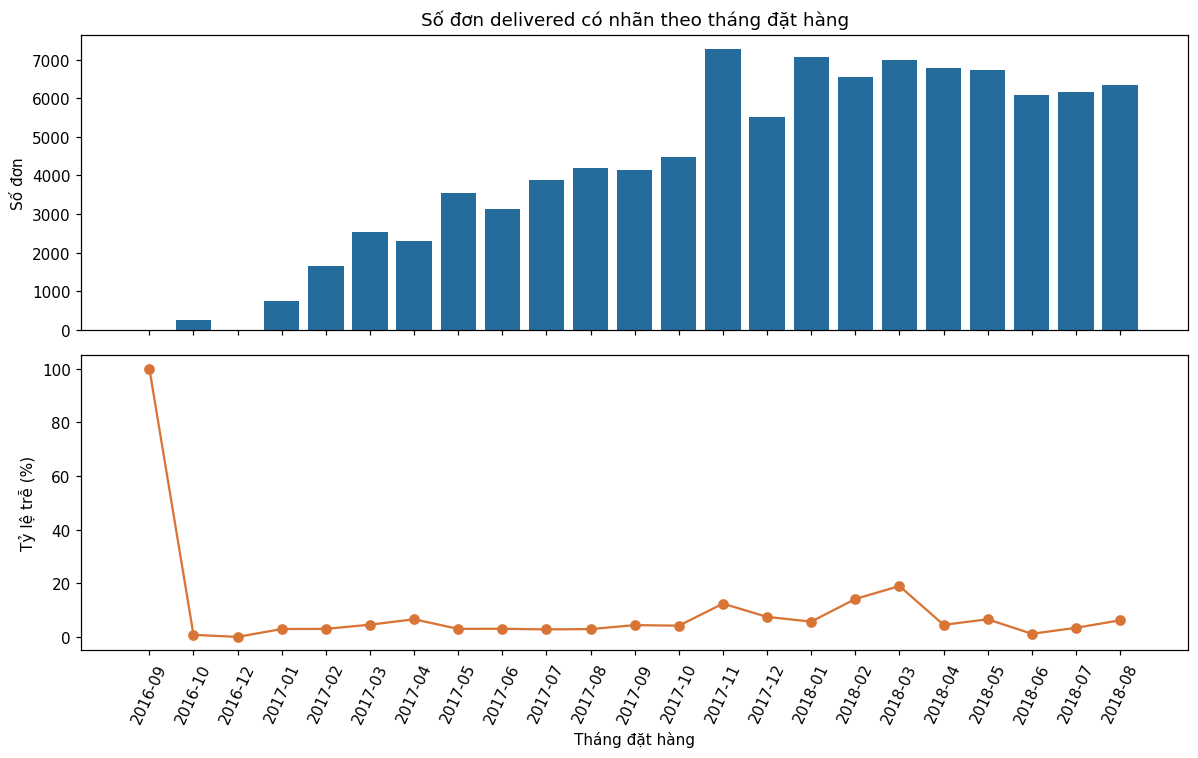

,purchase_month,orders,late_orders,late_rate
0,2016-09,1,1,1.000000
1,2016-10,265,2,0.007547
2,2016-12,1,0,0.000000
3,2017-01,748,22,0.029412
4,2017-02,1641,49,0.029860
5,2017-03,2546,116,0.045562
6,2017-04,2303,151,0.065567
7,2017-05,3545,106,0.029901
8,2017-06,3135,95,0.030303
9,2017-07,3872,108,0.027893


Trong các tháng có ít nhất 1.000 đơn (ngưỡng chỉ để đọc EDA), tháng 2018-03 có tỷ lệ trễ cao nhất: 18.96% trên 7,003 đơn; tháng 2018-06 là 1.16% trên 6,096 đơn. Những tháng đầu/cuối ít dữ liệu vẫn được giữ trên hình nhưng không dùng riêng để kết luận mùa vụ. Biến động này gợi ý cần đánh giá mô hình theo thời gian, thay vì chỉ chia ngẫu nhiên.

In [18]:
monthly=eda['purchase_month'].sort_values('purchase_month')
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].bar(monthly['purchase_month'].astype(str),monthly['orders'],color='#246C9C')
axes[0].set(ylabel='Số đơn',title='Số đơn delivered có nhãn theo tháng đặt hàng')
axes[1].plot(monthly['purchase_month'].astype(str),100*monthly['late_rate'],marker='o',color='#D87536')
axes[1].set(ylabel='Tỷ lệ trễ (%)',xlabel='Tháng đặt hàng')
axes[1].tick_params(axis='x',rotation=65)
fig.tight_layout(); fig.savefig(FIGURES/'ch03_monthly.png',bbox_inches='tight'); plt.show()

display(monthly)
large=monthly.loc[monthly['orders']>=1000]
peak=large.loc[large['late_rate'].idxmax()]; low=large.loc[large['late_rate'].idxmin()]
explain('month',f"Trong các tháng có ít nhất 1.000 đơn (ngưỡng chỉ để đọc EDA), tháng {peak['purchase_month']} có tỷ lệ trễ cao nhất: {peak['late_rate']:.2%} trên {int(peak['orders']):,} đơn; tháng {low['purchase_month']} là {low['late_rate']:.2%} trên {int(low['orders']):,} đơn. Những tháng đầu/cuối ít dữ liệu vẫn được giữ trên hình nhưng không dùng riêng để kết luận mùa vụ. Biến động này gợi ý cần đánh giá mô hình theo thời gian, thay vì chỉ chia ngẫu nhiên.")


### 3.4.2. Bang của khách hàng


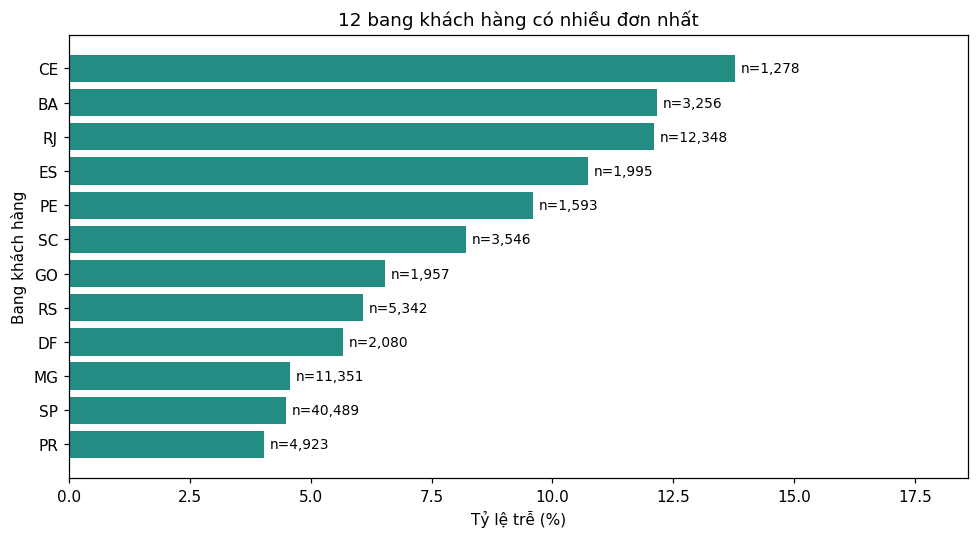

,customer_state,orders,late_orders,late_rate
17,PR,4923,199,0.040423
25,SP,40489,1820,0.044950
10,MG,11351,519,0.045723
6,DF,2080,118,0.056731
22,RS,5342,325,0.060839
8,GO,1957,128,0.065406
23,SC,3546,291,0.082064
15,PE,1593,153,0.096045
7,ES,1995,214,0.107268
18,RJ,12348,1495,0.121072


SP: 40,489 đơn, trễ 4.50%; RJ: 12,348 đơn, trễ 12.11%; BA: 3,256 đơn, trễ 12.16%. SP có nhiều đơn nhưng không phải bang có tỷ lệ trễ cao nhất. Khác biệt giữa các bang đáng để xem xét trong bài toán dự báo, nhưng biểu đồ chưa chứng minh địa lý là nguyên nhân gây trễ. customer_state được sử dụng trong baseline vì thông tin này có từ lúc đặt hàng.

In [19]:
state=eda['customer_state'].sort_values('orders',ascending=False).head(12).sort_values('late_rate')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(state['customer_state'],100*state['late_rate'],color='#238C83')
for i,(_,r) in enumerate(state.iterrows()):
    ax.text(100*r['late_rate']+.12,i,f"n={int(r['orders']):,}",va='center',fontsize=9)
ax.set(xlabel='Tỷ lệ trễ (%)',ylabel='Bang khách hàng',title='12 bang khách hàng có nhiều đơn nhất')
ax.set_xlim(0,max(100*state['late_rate'])*1.35)
fig.tight_layout();fig.savefig(FIGURES/'ch03_customer_states.png',bbox_inches='tight');plt.show()

display(state)
lookup=eda['customer_state'].set_index('customer_state')
text='; '.join(f"{k}: {int(lookup.loc[k,'orders']):,} đơn, trễ {lookup.loc[k,'late_rate']:.2%}" for k in ['SP','RJ','BA'])
explain('state',text+'. SP có nhiều đơn nhưng không phải bang có tỷ lệ trễ cao nhất. Khác biệt giữa các bang đáng để xem xét trong bài toán dự báo, nhưng biểu đồ chưa chứng minh địa lý là nguyên nhân gây trễ. customer_state được sử dụng trong baseline vì thông tin này có từ lúc đặt hàng.')


In [20]:
def group_chart(group, title, filename, ordered=False):
    table=eda[group].copy()
    if not ordered: table=table.sort_values('orders',ascending=False).head(10)
    labels=[f"{str(r[group]) if pd.notna(r[group]) else 'Thiếu dữ liệu'} (n={int(r['orders']):,})" for _,r in table.iterrows()]
    fig,ax=plt.subplots(figsize=(11,5))
    ax.barh(labels,100*table['late_rate'],color='#285378');ax.invert_yaxis()
    ax.set(xlabel='Tỷ lệ giao trễ (%)',title=title)
    fig.tight_layout();fig.savefig(FIGURES/filename,bbox_inches='tight');plt.show()
    display(table)
    return table


### 3.4.3. Bang người bán và đơn có nhiều bang người bán


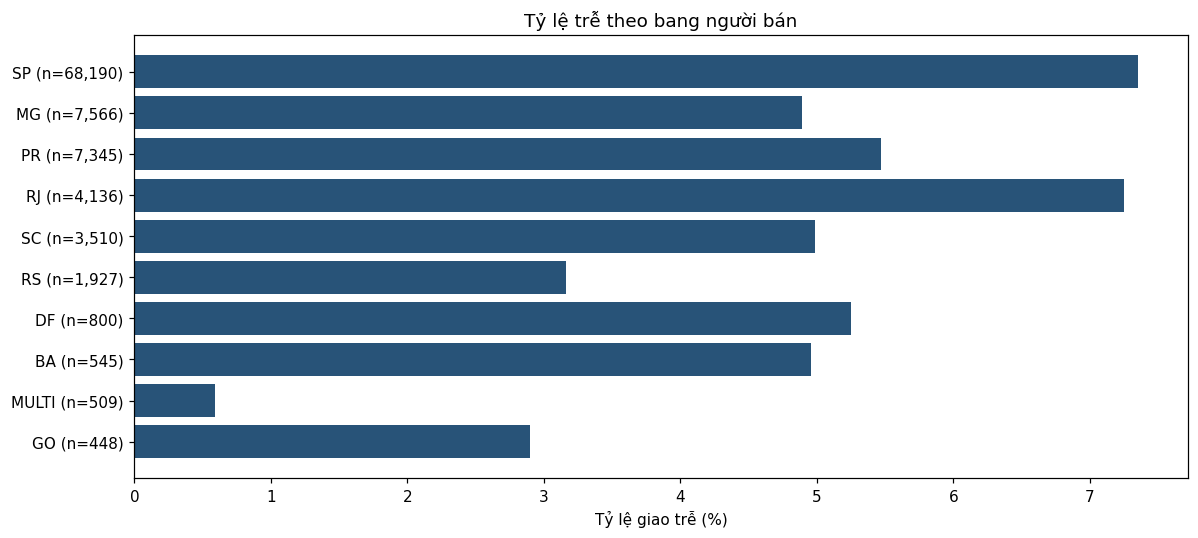

,seller_region,orders,late_orders,late_rate
22,SP,68190,5013,0.073515
7,MG,7566,370,0.048903
15,PR,7345,402,0.054731
16,RJ,4136,300,0.072534
20,SC,3510,175,0.049858
19,RS,1927,61,0.031655
3,DF,800,42,0.052500
1,BA,545,27,0.049541
10,MULTI,509,3,0.005894
5,GO,448,13,0.029018


SP: 68,190 đơn, trễ 7.35%; PR: 7,345 đơn, trễ 5.47%; MG: 7,566 đơn, trễ 4.89%; MULTI: 509 đơn, trễ 0.59%. MULTI là đơn có seller ở nhiều bang; nhiều seller cùng bang vẫn nằm trong bang đó. Vì vậy không đồng nhất nhóm này với toàn bộ đơn nhiều người bán. Các tỷ lệ là mô tả, chưa tách riêng ảnh hưởng của tuyến giao hàng hay loại sản phẩm. Thuộc tính seller không nằm trong baseline vì chưa có bằng chứng về thời điểm gán seller trong dữ liệu snapshot.

In [21]:
table=group_chart('seller_region','Tỷ lệ trễ theo bang người bán','ch03_seller_region.png')
selected=eda['seller_region'].set_index('seller_region')
text='; '.join(f"{k}: {int(selected.loc[k,'orders']):,} đơn, trễ {selected.loc[k,'late_rate']:.2%}" for k in ['SP','PR','MG','MULTI'] if k in selected.index)
explain('seller_region',text+'. MULTI là đơn có seller ở nhiều bang; nhiều seller cùng bang vẫn nằm trong bang đó. Vì vậy không đồng nhất nhóm này với toàn bộ đơn nhiều người bán. Các tỷ lệ là mô tả, chưa tách riêng ảnh hưởng của tuyến giao hàng hay loại sản phẩm. Thuộc tính seller không nằm trong baseline vì chưa có bằng chứng về thời điểm gán seller trong dữ liệu snapshot.')


### 3.4.4. Nhóm danh mục sản phẩm


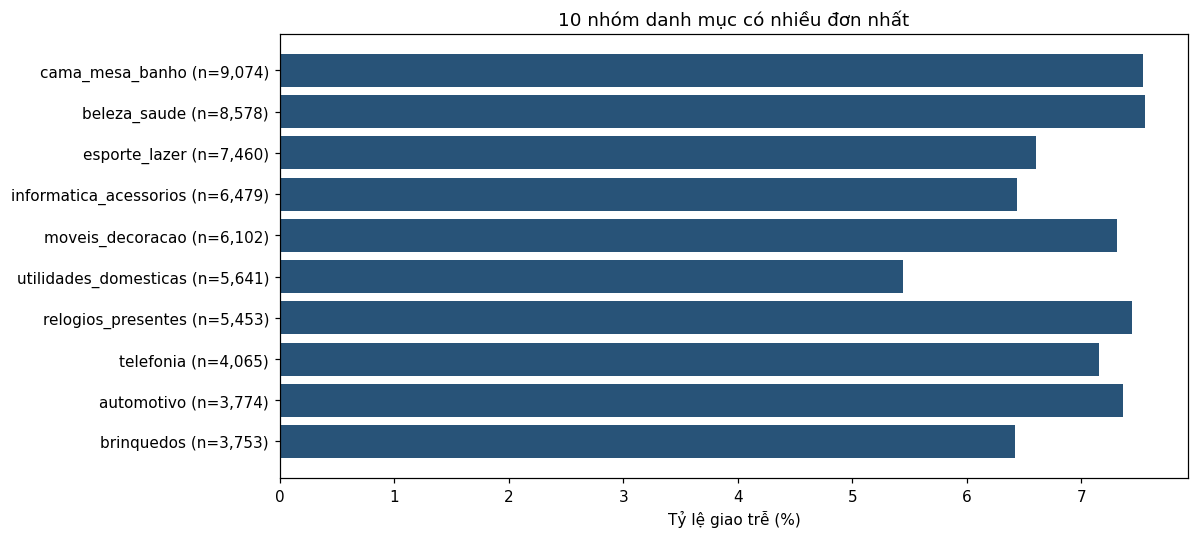

,product_category,orders,late_orders,late_rate
15,cama_mesa_banho,9074,684,0.075380
13,beleza_saude,8578,648,0.075542
34,esporte_lazer,7460,493,0.066086
46,informatica_acessorios,6479,417,0.064362
56,moveis_decoracao,6102,446,0.073091
74,utilidades_domesticas,5641,307,0.054423
68,relogios_presentes,5453,406,0.074454
72,telefonia,4065,291,0.071587
10,automotivo,3774,278,0.073662
14,brinquedos,3753,241,0.064215


cama_mesa_banho: 9,074 đơn, trễ 7.54%; beleza_saude: 8,578 đơn, trễ 7.55%; esporte_lazer: 7,460 đơn, trễ 6.61%; informatica_acessorios: 6,479 đơn, trễ 6.44%. Đơn có nhiều danh mục được gắn MULTI; thiếu toàn bộ danh mục được gắn UNKNOWN. Đây là phân nhóm ở cấp đơn, không phải số lượng sản phẩm bán ra. Chênh lệch tỷ lệ trễ giữa các danh mục chưa chứng minh tác động riêng của loại hàng, nên biến này chỉ được dùng cho EDA trong phạm vi nghiên cứu hiện tại.

In [22]:
table=group_chart('product_category','10 nhóm danh mục có nhiều đơn nhất','ch03_product_category.png')
text='; '.join(f"{r['product_category']}: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.head(4).iterrows())
explain('category',text+'. Đơn có nhiều danh mục được gắn MULTI; thiếu toàn bộ danh mục được gắn UNKNOWN. Đây là phân nhóm ở cấp đơn, không phải số lượng sản phẩm bán ra. Chênh lệch tỷ lệ trễ giữa các danh mục chưa chứng minh tác động riêng của loại hàng, nên biến này chỉ được dùng cho EDA trong phạm vi nghiên cứu hiện tại.')


### 3.4.5. Giá trị sản phẩm trong đơn


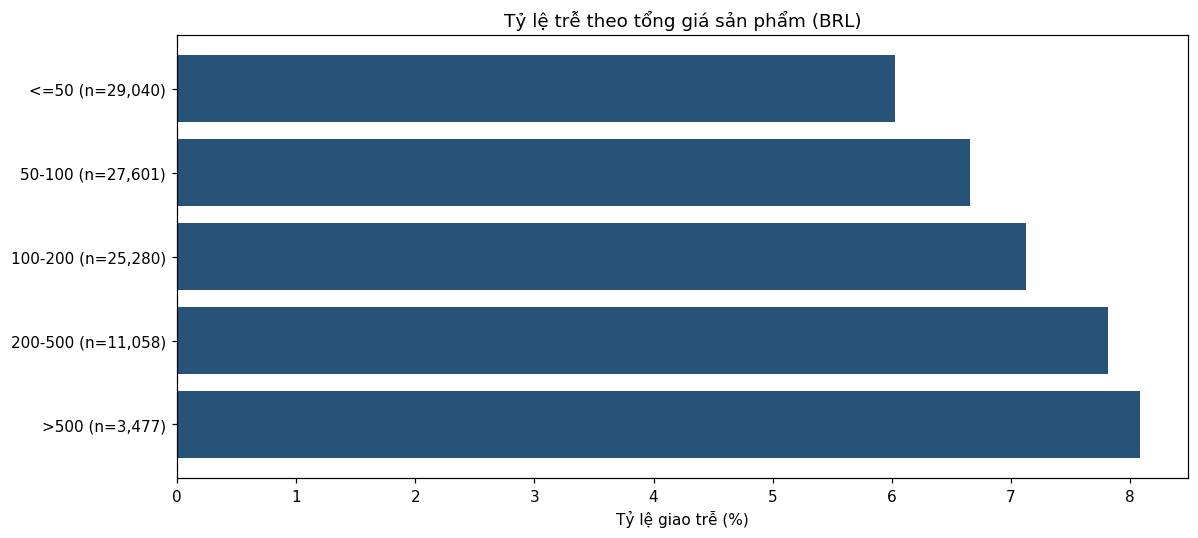

,order_value_group,orders,late_orders,late_rate
0,<=50,29040,1750,0.060262
1,50-100,27601,1838,0.066592
2,100-200,25280,1801,0.071242
3,200-500,11058,864,0.078133
4,>500,3477,281,0.080817


<=50 BRL: 29,040 đơn, trễ 6.03%; 50-100 BRL: 27,601 đơn, trễ 6.66%; 100-200 BRL: 25,280 đơn, trễ 7.12%; 200-500 BRL: 11,058 đơn, trễ 7.81%; >500 BRL: 3,477 đơn, trễ 8.08%. Các khoảng được hiểu là (50,100], (100,200], (200,500]; nhóm đầu gồm giá trị ≤50. total_price là tổng giá sản phẩm, chưa gồm phí vận chuyển, không đồng nghĩa tổng thanh toán. Trên mẫu đang xét, tỷ lệ trễ tăng theo các nhóm giá; đây là liên hệ mô tả, chưa thể kết luận đơn đắt hơn gây giao trễ.

In [23]:
table=group_chart('order_value_group','Tỷ lệ trễ theo tổng giá sản phẩm (BRL)','ch03_order_value_group.png',ordered=True)
text='; '.join(f"{r['order_value_group']} BRL: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.iterrows())
explain('value',text+'. Các khoảng được hiểu là (50,100], (100,200], (200,500]; nhóm đầu gồm giá trị ≤50. total_price là tổng giá sản phẩm, chưa gồm phí vận chuyển, không đồng nghĩa tổng thanh toán. Trên mẫu đang xét, tỷ lệ trễ tăng theo các nhóm giá; đây là liên hệ mô tả, chưa thể kết luận đơn đắt hơn gây giao trễ.')


### 3.4.6. Khối lượng trung bình của item


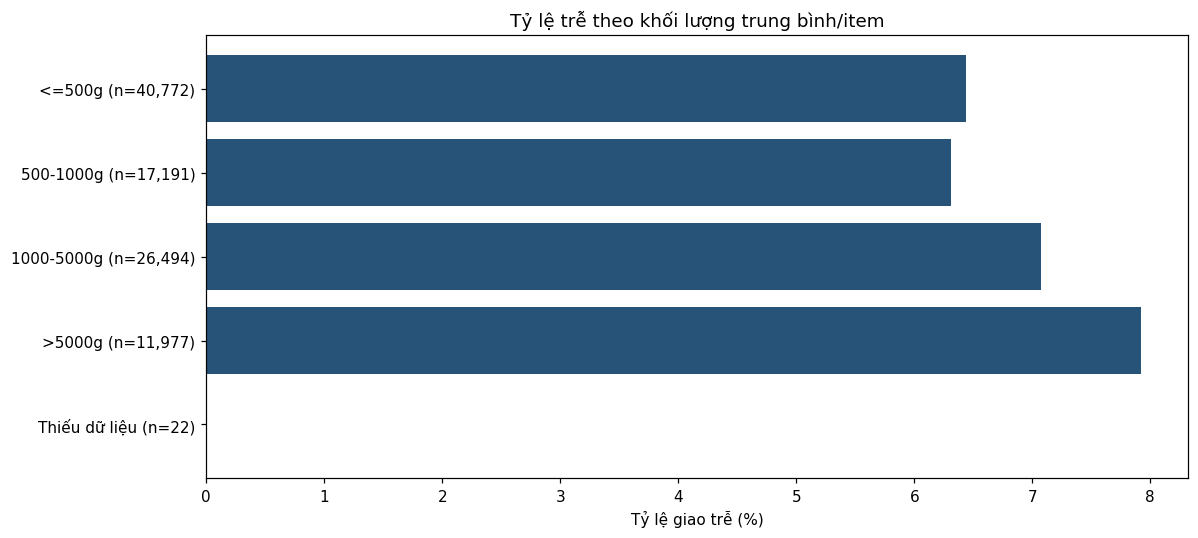

,weight_group,orders,late_orders,late_rate
0,<=500g,40772,2625,0.064382
1,500-1000g,17191,1085,0.063114
2,1000-5000g,26494,1875,0.070771
3,>5000g,11977,949,0.079235
4,NaN,22,0,0.000000


<=500g: 40,772 đơn, trễ 6.44%; 500-1000g: 17,191 đơn, trễ 6.31%; 1000-5000g: 26,494 đơn, trễ 7.08%; >5000g: 11,977 đơn, trễ 7.92%; Thiếu khối lượng: 22 đơn, trễ 0.00%. avg_weight_g là trung bình khối lượng của các item có số đo, không phải tổng khối lượng kiện hàng. weight_known_items cho biết số item có thông tin để tránh xem trung bình thiếu dữ liệu là đầy đủ. Không điền khối lượng thiếu bằng 0; nhóm thiếu được trình bày riêng. Kết quả chưa tách tác động của khoảng cách giao hàng và danh mục sản phẩm.

In [24]:
table=group_chart('weight_group','Tỷ lệ trễ theo khối lượng trung bình/item','ch03_weight_group.png',ordered=True)
text='; '.join(f"{str(r['weight_group']) if pd.notna(r['weight_group']) else 'Thiếu khối lượng'}: {int(r['orders']):,} đơn, trễ {r['late_rate']:.2%}" for _,r in table.iterrows())
explain('weight',text+'. avg_weight_g là trung bình khối lượng của các item có số đo, không phải tổng khối lượng kiện hàng. weight_known_items cho biết số item có thông tin để tránh xem trung bình thiếu dữ liệu là đầy đủ. Không điền khối lượng thiếu bằng 0; nhóm thiếu được trình bày riêng. Kết quả chưa tách tác động của khoảng cách giao hàng và danh mục sản phẩm.')


### 3.4.7. Kiểm tra ở cấp mã người bán


In [25]:
seller_view=eda_seller.sort_values('orders',ascending=False).head(10)
display(seller_view)
explain('seller_id','Bảng trên là 10 seller có nhiều đơn được gán nhãn nhất, không phải bảng xếp hạng chất lượng người bán. Một đơn nhiều seller được tính một lần trong từng seller liên quan, nên tổng số đơn giữa các seller có thể lớn hơn tổng đơn toàn bộ. Tỷ lệ trễ dựa vào kết quả giao của cả đơn; chưa đủ căn cứ quy trách nhiệm cho từng seller. Cách đếm ở bảng này là cơ sở để giữ nhất quán các lát cắt theo seller khi phân tích lỗi ở Chương 5.')


,seller_id,orders,late_orders,late_rate
1190,6560211a19b47992c3666cc44a7e94c0,1819,96,0.052776
858,4a3ca9315b744ce9f8e9374361493884,1772,172,0.097065
2388,cc419e0650a3c5ba77189a1882b7556a,1651,87,0.052695
358,1f50f920176fa81dab994f9023523100,1399,124,0.088635
2543,da8622b14eb17ae2831f4ac5b9dab84a,1311,87,0.066362
1758,955fee9216a65b617aa5c0531780ce60,1261,77,0.061063
1450,7a67c85e85bb2ce8582c35f2203ad736,1142,60,0.052539
2725,ea8482cd71df3c1969d7b9473ff13abc,1132,96,0.084806
834,4869f7a5dfa277a7dca6462dcf3b52b2,1124,118,0.104982
712,3d871de0142ce09b7081e2b9d1733cb1,1064,58,0.054511


Bảng trên là 10 seller có nhiều đơn được gán nhãn nhất, không phải bảng xếp hạng chất lượng người bán. Một đơn nhiều seller được tính một lần trong từng seller liên quan, nên tổng số đơn giữa các seller có thể lớn hơn tổng đơn toàn bộ. Tỷ lệ trễ dựa vào kết quả giao của cả đơn; chưa đủ căn cứ quy trách nhiệm cho từng seller. Cách đếm ở bảng này là cơ sở để giữ nhất quán các lát cắt theo seller khi phân tích lỗi ở Chương 5.

### 3.4.8. Kết luận từ EDA
Tỷ lệ giao trễ của mẫu thấp hơn nhiều tỷ lệ đúng hạn, nên ở phần mô hình nhóm cần xem Precision, Recall và AP thay vì chỉ dựa vào Accuracy. EDA cũng cho thấy tỷ lệ trễ thay đổi theo thời gian, bang khách hàng và nhóm giá trị đơn. Các khác biệt này giúp đặt câu hỏi phân tích, chưa đủ để kết luận nguyên nhân hoặc chứng minh một feature sẽ cải thiện mô hình. Những biến chưa rõ thời điểm xuất hiện tiếp tục được giữ ngoài baseline.


## 3.5. Xây dựng đặc trưng và kiểm soát rò rỉ thông tin

Bộ đặc trưng cơ sở gồm tháng đặt hàng, thứ trong tuần, giờ đặt hàng, thời gian từ đặt đến phê duyệt và bang khách hàng. Các trường này có thể xác định tại hoặc trước `order_approved_at`. Những thuộc tính chưa có bằng chứng về thời điểm xuất hiện được giữ ngoài baseline, dù vẫn có ích cho EDA.

Bảng xuất có **37 cột**, gồm cả đặc trưng, nhãn, khóa, thời gian đối soát và cờ chất lượng. Vì vậy, X được tạo từ danh sách cho phép riêng. Ngày giao thực tế, ngày bàn giao vận chuyển, trạng thái cuối cùng và đánh giá không được dùng làm đặc trưng dự báo sớm.


### 3.5.1. Bộ đặc trưng cơ sở
| Đặc trưng | Cách tạo | Ý nghĩa |
|---|---|---|
| purchase_month_number | Tháng của order_purchase_timestamp | Tháng đặt hàng, từ 1 đến 12 |
| purchase_weekday | Thứ của order_purchase_timestamp | 0 là thứ Hai, 6 là Chủ nhật |
| purchase_hour | Giờ của order_purchase_timestamp | Giờ đặt hàng, từ 0 đến 23 |
| approval_delay_hours | (order_approved_at − order_purchase_timestamp)/1 giờ | Thời gian từ đặt đến duyệt |
| customer_state | Nối customers qua customer_id | Bang nhận hàng của khách |

Các đặc trưng chỉ được tính toán từ trường có sẵn. Notebook không fit imputer, encoder hay scaler trên toàn bộ dữ liệu.


In [26]:
model_data['purchase_month_number']=model_data['order_purchase_timestamp'].dt.month
model_data['purchase_weekday']=model_data['order_purchase_timestamp'].dt.weekday
model_data['purchase_hour']=model_data['order_purchase_timestamp'].dt.hour
model_data['approval_delay_hours']=(model_data['order_approved_at']-model_data['order_purchase_timestamp']).dt.total_seconds()/3600
SAFE_FEATURES=['purchase_month_number','purchase_weekday','purchase_hour','approval_delay_hours','customer_state']
FORBIDDEN=['order_delivered_customer_date','order_delivered_carrier_date','order_status','review_score']
assert not set(SAFE_FEATURES).intersection(FORBIDDEN)
assert set(SAFE_FEATURES).issubset(model_data.columns)
assert not model_data['approval_delay_hours'].dropna().lt(0).any()
(PROCESSED/'feature_whitelist.json').write_text(json.dumps(SAFE_FEATURES,ensure_ascii=False,indent=2),encoding='utf-8')
output=PROCESSED/'orders_model_ready.csv'
model_data.to_csv(output,index=False)
base.to_csv(PROCESSED/'orders_analysis_all_status.csv',index=False)
# Kiểm tra trực tiếp file đã ghi, không chỉ DataFrame trong RAM.
check=pd.read_csv(output,dtype={'order_id':'string'})
assert len(check)==len(model_data) and check['order_id'].is_unique
assert check['is_late'].isin([0,1]).all()
assert check['is_late'].sum()==model_data['is_late'].sum()
display(model_data[SAFE_FEATURES].head())
print('Đã xuất', len(model_data), 'đơn có nhãn; số cột:', model_data.shape[1])

BASELINE_FILE=PROCESSED/'orders_baseline_input.csv'
model_data[['order_id','is_late']+SAFE_FEATURES].to_csv(BASELINE_FILE,index=False)
model_data[['order_id','order_purchase_timestamp','order_approved_at','order_delivered_customer_date']].to_csv(PROCESSED/'orders_split_metadata.csv',index=False)
print('Đầu vào baseline riêng:',len(SAFE_FEATURES),'feature + order_id + is_late.')


,purchase_month_number,purchase_weekday,purchase_hour,approval_delay_hours,customer_state
0,10,0,10,0.178333,SP
1,7,1,20,30.713889,BA
2,8,2,8,0.276111,GO
3,11,5,19,0.298056,RN
4,2,1,21,1.030556,SP


Đã xuất 96456 đơn có nhãn; số cột: 37
Đầu vào baseline riêng: 5 feature + order_id + is_late.


### 3.5.2. Vai trò từng cột và từ điển dữ liệu


In [27]:
MEANINGS={
'order_id':'Mã đơn hàng','customer_id':'Mã bản ghi khách hàng liên kết đơn',
'customer_unique_id':'Mã nhận diện khách hàng xuyên các đơn','order_status':'Trạng thái cuối quan sát',
'order_purchase_timestamp':'Thời điểm đặt đơn','order_approved_at':'Thời điểm phê duyệt, t0 dự báo',
'order_delivered_carrier_date':'Thời điểm bàn giao vận chuyển, hậu nghiệm',
'order_delivered_customer_date':'Thời điểm giao khách, dùng tạo nhãn',
'order_estimated_delivery_date':'Ngày giao dự kiến, dùng tạo nhãn; feature cần xác minh',
'order_item_id':'Số thứ tự item trong đơn','product_id':'Mã sản phẩm','seller_id':'Mã người bán',
'shipping_limit_date':'Hạn bàn giao vận chuyển, cần xác minh tại t0','price':'Giá item, BRL',
'freight_value':'Phí vận chuyển item, BRL','payment_sequential':'Thứ tự bản ghi thanh toán trong đơn',
'payment_type':'Loại thanh toán','payment_installments':'Số kỳ trả góp, 0 cần review',
'payment_value':'Giá trị thanh toán, BRL','review_id':'Mã đánh giá; không ép duy nhất trên toàn bảng',
'review_score':'Điểm đánh giá 1–5','review_comment_title':'Tiêu đề tùy chọn, thiếu có thể hợp lệ',
'review_comment_message':'Nội dung tùy chọn, thiếu có thể hợp lệ','review_creation_date':'Ngày tạo đánh giá',
'review_answer_timestamp':'Thời điểm trả lời đánh giá','product_category_name':'Danh mục tiếng Bồ Đào Nha',
'product_category_name_english':'Bản dịch danh mục tiếng Anh','product_name_lenght':'Độ dài tên sản phẩm, tên cột gốc',
'product_description_lenght':'Độ dài mô tả, tên cột gốc','product_photos_qty':'Số ảnh sản phẩm',
'product_weight_g':'Trọng lượng gram; <=0 chuyển NA theo quy tắc làm sạch',
'product_length_cm':'Chiều dài cm','product_height_cm':'Chiều cao cm','product_width_cm':'Chiều rộng cm',
'geolocation_lat':'Vĩ độ','geolocation_lng':'Kinh độ'}
for prefix in ['customer','seller','geolocation']:
    MEANINGS[prefix+'_zip_code_prefix']='Tiền tố mã bưu chính, chuỗi 5 chữ số'
    MEANINGS[prefix+'_city']='Thành phố, chỉ chuẩn hóa chuỗi'
    MEANINGS[prefix+'_state']='Mã bang Brazil'
KEYS={'orders':['order_id'],'items':['order_id','order_item_id'],'customers':['customer_id'],
      'sellers':['seller_id'],'products':['product_id'],'payments':['order_id','payment_sequential'],
      'reviews':['review_id','order_id'],'translation':['product_category_name'],'geolocation':[]}
dictionary=[]
for name,d in clean.items():
    for c in raw[name].columns:
        dictionary.append({'table':name,'column':c,'meaning':MEANINGS.get(c,'Xem mô tả nguồn'),
                           'clean_dtype':str(d[c].dtype),'part_of_checked_key':c in KEYS[name],
                           'missing_after':int(d[c].isna().sum())})
pd.DataFrame(dictionary).to_csv(TABLES/'data_dictionary.csv',index=False)

DETAILS={
 'order_id':('metadata','orders','Khóa đối soát, không làm X'),
 'customer_id':('metadata','orders/customers','Khóa liên kết, không làm X'),
 'order_status':('forbidden_feature','orders','Trạng thái cuối dùng chọn mẫu'),
 'order_purchase_timestamp':('metadata','orders','Nguồn tạo các feature thời gian'),
 'order_approved_at':('metadata','orders','Mốc t0 và chia tập thời gian'),
 'order_delivered_carrier_date':('forbidden_feature','orders','Mốc sau phê duyệt'),
 'order_delivered_customer_date':('forbidden_feature','orders','Chỉ tạo nhãn và kiểm tra nhãn đủ chín'),
 'order_estimated_delivery_date':('excluded_unverified','orders','Dùng tạo nhãn; nếu làm feature phải chứng minh có tại t0'),
 'customer_state':('baseline_feature','customers','Bang khách tại lúc đặt/duyệt'),
 'is_late':('target','orders','DATE(actual)>DATE(estimated), chỉ delivered đủ ngày'),
 'item_count':('excluded_unverified','order_items','Số dòng item/đơn'),
 'product_count':('excluded_unverified','order_items','Số product_id khác nhau/đơn'),
 'seller_count':('excluded_unverified','order_items','Số seller_id khác nhau/đơn'),
 'total_price':('excluded_unverified','order_items','Tổng price, BRL; không bao gồm freight'),
 'total_freight':('excluded_unverified','order_items','Tổng freight_value, BRL'),
 'price_known_items':('qa_metadata','order_items','Số item có giá'),
 'freight_known_items':('qa_metadata','order_items','Số item có phí'),
 'avg_weight_g':('excluded_unverified','products + items','Trung bình gram/item có số đo, không phải tổng kiện'),
 'weight_known_items':('qa_metadata','products + items','Số item có khối lượng'),
 'seller_region':('excluded_unverified','sellers + items','Một bang hoặc MULTI nếu nhiều bang'),
 'product_category':('excluded_unverified','products + items','Một category hoặc MULTI nếu nhiều category'),
 'total_payment':('excluded_unverified','payments','Tổng thanh toán theo đơn'),
 'payment_records':('excluded_unverified','payments','Số bản ghi thanh toán theo đơn'),
 'purchase_month':('eda_only','orders','Tháng YYYY-MM để vẽ EDA'),
 'order_value_group':('eda_only','items','Nhóm total_price dùng cho EDA'),
 'weight_group':('eda_only','products + items','Nhóm avg_weight_g dùng cho EDA'),
 'purchase_month_number':('baseline_feature','orders','Tháng đặt hàng, 1–12'),
 'purchase_weekday':('baseline_feature','orders','Thứ đặt hàng, 0=thứ Hai, 6=Chủ nhật'),
 'purchase_hour':('baseline_feature','orders','Giờ đặt hàng, 0–23'),
 'approval_delay_hours':('baseline_feature','orders','(approved - purchase), giờ')}
for c in model_data.filter(like='qa_').columns:
    DETAILS[c]=('qa_metadata','orders','Cờ QA; có thể dùng thời gian tương lai, không làm X')
assert set(DETAILS)==set(model_data.columns), 'Schema chưa bao phủ đúng các cột xuất'
schema=pd.DataFrame([{'column':c,'dtype':str(model_data[c].dtype),'missing':int(model_data[c].isna().sum()),
                     'role':DETAILS[c][0],'source':DETAILS[c][1],'meaning':DETAILS[c][2],
                     'use_in_X':c in SAFE_FEATURES,
                     'feature_policy':'baseline_at_t0' if c in SAFE_FEATURES else 'not_in_baseline'}
                    for c in model_data.columns])
schema.to_csv(TABLES/'model_data_schema.csv',index=False)
feature_registry=schema.rename(columns={'column':'feature'}).copy()
feature_registry['present_in_export']=True
feature_registry=pd.concat([feature_registry,pd.DataFrame([
 {'feature':'shipping_limit_date','source':'items','role':'excluded_unverified','meaning':'Có ở bảng item, không có trong bảng cấp đơn hiện tại','use_in_X':False,'present_in_export':False},
 {'feature':'review_score','source':'reviews','role':'forbidden_feature','meaning':'Thông tin đánh giá hậu nghiệm, không làm đầu vào dự báo sớm','use_in_X':False,'present_in_export':False}
])],ignore_index=True)
feature_registry.to_csv(TABLES/'feature_registry.csv',index=False)
manifest={
 'notebook_version':'lam_linh_ch03_final_20261107', 'source_files':source_records,
 'model_file':output.name,'model_sha256':hashlib.sha256(output.read_bytes()).hexdigest(),
 'rows':len(model_data),'columns':model_data.shape[1],'late_orders':int(model_data['is_late'].sum()),
 'late_rate':float(model_data['is_late'].mean()),'features':SAFE_FEATURES,
 'baseline_file':BASELINE_FILE.name,'feature_policy':'five_baseline_features_only',
 'label':'DATE(actual)>DATE(estimated), delivered with approved+actual+estimated',
 'chronology_policy':'retain flagged rows in labeled cohort; provide chronology sensitivity; flags excluded from X',
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__}}
(PROCESSED/'data_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
with pd.option_context('display.max_rows',60,'display.max_columns',8,'display.max_colwidth',70):display(schema)
display(schema.groupby('role').size().rename('columns').to_frame())
print('Từ điển:',len(dictionary),'dòng mô tả cột theo từng bảng. Schema:',len(schema),'cột.')


,column,dtype,missing,role,source,meaning,use_in_X,feature_policy
0,order_id,string,0,metadata,orders,"Khóa đối soát, không làm X",False,not_in_baseline
1,customer_id,string,0,metadata,orders/customers,"Khóa liên kết, không làm X",False,not_in_baseline
2,order_status,string,0,forbidden_feature,orders,Trạng thái cuối dùng chọn mẫu,False,not_in_baseline
3,order_purchase_timestamp,datetime64[ns],0,metadata,orders,Nguồn tạo các feature thời gian,False,not_in_baseline
4,order_approved_at,datetime64[ns],0,metadata,orders,Mốc t0 và chia tập thời gian,False,not_in_baseline
5,order_delivered_carrier_date,datetime64[ns],1,forbidden_feature,orders,Mốc sau phê duyệt,False,not_in_baseline
6,order_delivered_customer_date,datetime64[ns],0,forbidden_feature,orders,Chỉ tạo nhãn và kiểm tra nhãn đủ chín,False,not_in_baseline
7,order_estimated_delivery_date,datetime64[ns],0,excluded_unverified,orders,Dùng tạo nhãn; nếu làm feature phải chứng minh có tại t0,False,not_in_baseline
8,qa_unknown_status,bool,0,qa_metadata,orders,"Cờ QA; có thể dùng thời gian tương lai, không làm X",False,not_in_baseline
9,qa_approved_before_purchase,bool,0,qa_metadata,orders,"Cờ QA; có thể dùng thời gian tương lai, không làm X",False,not_in_baseline


,columns
role,
baseline_feature,5
eda_only,3
excluded_unverified,11
forbidden_feature,3
metadata,4
qa_metadata,10
target,1


Từ điển: 52 dòng mô tả cột theo từng bảng. Schema: 37 cột.


### 3.5.3. Cấu trúc đầu ra
| Tệp hoặc nhóm kết quả | Nội dung | Mục đích sử dụng |
|---|---|---|
| orders_baseline_input.csv | order_id, is_late và 5 đặc trưng | Tách khóa, y và X theo whitelist |
| orders_split_metadata.csv | Khóa đơn, ngày đặt, ngày duyệt và ngày giao thực tế | Chia tập theo thời gian và kiểm tra thời điểm nhãn hình thành |
| orders_model_ready.csv | 37 cột của tập có nhãn | Đối soát và phân tích; không dùng toàn bộ làm X |
| orders_analysis_all_status.csv | Toàn bộ 99.441 đơn và nhãn nếu xác định được | Mô tả các trạng thái, theo dõi mẫu loại |
| feature_whitelist.json, feature_registry.csv, model_data_schema.csv | Danh sách cho phép và vai trò từng cột | Kiểm soát đầu vào mô hình |
| 9 CSV sạch, geolocation_by_zip.csv, data_dictionary.csv | Dữ liệu sau xử lý và mô tả cấu trúc | Tái lập xử lý và phân tích |
| Các bảng QA, bảng EDA, hình và data_manifest.json | Kiểm tra chất lượng, thống kê và hash | Đối chiếu kết quả giữa các bước |

Ngày giao thực tế trong metadata chỉ phục vụ kiểm tra nhãn đã hình thành trước mốc cắt dữ liệu. Các thao tác học tham số tiền xử lý thuộc bước huấn luyện: fit trên Train, sau đó chỉ transform Validation/Test.


### 3.5.4. Lưu nội dung báo cáo
Nội dung báo cáo và các bảng tổng hợp được xuất từ cùng kết quả xử lý để giữ thống nhất giữa notebook, số liệu và hình minh họa.


In [28]:
CHAPTERS=ROOT/'reports'/'chapters';CHAPTERS.mkdir(parents=True,exist_ok=True)
report = '# CHƯƠNG 3. DỮ LIỆU VÀ PHƯƠNG PHÁP XỬ LÝ\n\nNgười thực hiện: Lam Linh — Nhóm 02.\n\n'
report += '## 3.1. Nguồn và cấu trúc dữ liệu\n\nNghiên cứu sử dụng 9 CSV của Brazilian E-Commerce Public Dataset by Olist [1], phản ánh đơn hàng tại Brazil giai đoạn 2016–2018. Giấy phép công bố trên trang nguồn là CC BY-NC-SA 4.0. Dữ liệu raw được giữ nguyên, mỗi tệp có mã SHA256 để đối chiếu. Khi tải repository dùng Git LFS, chạy git lfs install và git lfs pull để lấy đủ CSV.\n\n'
report += md_table(profile)+'\n\n![Hình 3.1. ERD Olist](../figures/ch03_erd.png)\n\n'
report += 'Orders là bảng trung tâm; items và payments cần tổng hợp trước khi nối. Một người mua có thể đặt nhiều đơn, nhưng customer_id trong Olist gắn riêng từng đơn; customer_unique_id nhận diện người mua lặp. Vì vậy, phép nối theo customer_id quan sát là 1:1. Reviews kiểm tra khóa ghép review_id/order_id. Geo được tổng hợp theo ZIP, translation có danh mục chưa khớp.\n\n'
report += '## 3.2. Tích hợp và làm sạch\n\nCác bước xử lý gồm chuẩn hóa chuỗi, mã ZIP, kiểu ngày và số, loại dòng trùng hoàn toàn, kiểm tra khóa và gắn cờ QA. Ngày giao thiếu không được điền giả; đánh giá không bị xóa chỉ vì thiếu bình luận. Trọng lượng không hợp lệ được chuyển thành thiếu, giữ giá trị gốc để đối chiếu.\n\n'
report += md_table(clean_summary)+'\n\n'+md_table(fk_report)+'\n\n'
report += 'Geolocation giảm số dòng do bỏ trùng. Missing của reviews tăng khi chuẩn hóa chuỗi trắng; missing của products tăng khi chuyển số đo không hợp lệ thành NaN. Số dòng có cờ QA đếm mỗi dòng tối đa một lần. Các cờ không đồng nghĩa mọi bản ghi đó đều sai hoặc đã được sửa.\n\n'
report += 'Mỗi order_id có đúng một dòng sau tích hợp. Items được nối sản phẩm/người bán và tổng hợp theo đơn; payments được tổng hợp riêng. Cardinality và tổng tiền được đối soát trước/sau join.\n\n'+md_table(join_audit)+'\n\n'+md_table(reconciliation.round(6))+'\n\n'
report += '## 3.3. Nhãn và chọn mẫu\n\nis_late=1 nếu DATE(ngày giao thực tế)>DATE(ngày giao dự kiến), ngược lại bằng 0. Chỉ gán nhãn cho delivered có đủ ngày duyệt, ngày giao và ngày dự kiến; đơn chưa đủ điều kiện không được gán nhãn 0.\n\n'+md_table(exclusion_table)+'\n\n![Hình 3.2. Chọn mẫu](../figures/ch03_label_flow.png)\n\n'+NARRATIVES['label']+'\n\n'+md_table(sensitivity.round(6))+'\n\n'
report += '## 3.4. Phân tích khám phá\n\nEDA mô tả tập delivered có nhãn. Các kết quả được đọc cùng cỡ mẫu và không được diễn giải như quan hệ nhân quả hoặc kết quả đánh giá mô hình.\n\n'
for heading,key,filename in [('Theo tháng','month','ch03_monthly.png'),('Bang khách hàng','state','ch03_customer_states.png'),('Bang người bán','seller_region','ch03_seller_region.png'),('Danh mục','category','ch03_product_category.png'),('Giá trị đơn','value','ch03_order_value_group.png'),('Khối lượng','weight','ch03_weight_group.png')]:
    report += f'### {heading}\n\n![{heading}](../figures/{filename})\n\n'+NARRATIVES[key]+'\n\n'
report += '### Mã người bán\n\n'+md_table(seller_view.round(6))+'\n\n'+NARRATIVES['seller_id']+'\n\n'
report += '## 3.5. Đặc trưng và kiểm soát rò rỉ thông tin\n\nTập có nhãn gồm 37 cột phục vụ các vai trò khác nhau. X chỉ gồm 5 feature baseline trong whitelist. orders_baseline_input.csv chứa khóa đơn, nhãn và 5 feature; metadata chia tập nằm ở tệp riêng.\n\n'
report += md_table(schema[['column','role','source','meaning','use_in_X']])+'\n\n'
report += 'Ngày giao thực tế chỉ tạo nhãn/kiểm tra nhãn trước cutoff. Carrier date, trạng thái cuối, review_score và cờ dùng thông tin tương lai không làm feature. Thuộc tính chưa rõ thời điểm xuất hiện chỉ dùng cho EDA. Imputer, encoder và scaler được fit trên Train ở bước huấn luyện.\n\n'
report += '### Kết luận chương\n\nChín bảng dữ liệu đã được chuẩn hóa và kiểm tra, tạo được 96.456 đơn có nhãn, trong đó 6.534 đơn giao trễ (6,77%). EDA cho thấy tỷ lệ trễ khác nhau theo thời gian, bang khách hàng và nhóm giá trị đơn. Giới hạn chính là mẫu chỉ gồm delivered đủ nhãn và còn những timestamp bất thường được ghi cờ. Các kết quả không đại diện cho toàn bộ đơn đang vận hành hoặc thị trường Việt Nam.\n\n'
report += '## Tài liệu tham khảo\n\n[1] Olist. Brazilian E-Commerce Public Dataset by Olist. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (truy cập 07/11/2026).\n'
(CHAPTERS/'CH03_DATA.md').write_text(report,encoding='utf-8')
# Khôi phục tài nguyên ERD đính kèm khi xuất báo cáo ra thư mục dự án.
notebook_paths=[HERE/'03_LAM_LINH_CHUONG_3_NOP_BAI.ipynb',ROOT/'notebooks'/'03_LAM_LINH_CHUONG_3_NOP_BAI.ipynb']
nb_path=next((p for p in notebook_paths if p.is_file()),None)
if nb_path is not None:
    document=json.loads(nb_path.read_text(encoding='utf-8'))
    for cell in document['cells']:
        asset=cell.get('attachments',{}).get('ERD_Olist.png',{})
        if 'image/png' in asset:
            (FIGURES/'ch03_erd.png').write_bytes(base64.b64decode(asset['image/png']))
    source_erd=document.get('metadata',{}).get('erd_source',{})
    if 'xml_base64' in source_erd:
        diagrams=ROOT/'reports'/'diagrams';diagrams.mkdir(parents=True,exist_ok=True)
        (diagrams/'ERD.drawio').write_bytes(base64.b64decode(source_erd['xml_base64']))
print('Đã lưu báo cáo Chương 3 và các tài nguyên minh họa.')


Đã lưu báo cáo Chương 3 và các tài nguyên minh họa.


### 3.5.5. Kiểm tra tính nhất quán của đầu ra


In [29]:
expected_clean=[CLEAN_DIR/(Path(filename).stem+'_clean.csv') for filename in NAMES.values()]
assert all(p.is_file() for p in expected_clean)
assert model_data['order_id'].notna().all() and model_data['order_id'].is_unique
assert len(model_data)+exclusion_table['excluded_orders'].sum()==len(orders)
assert not model_data['is_late'].isna().any()
assert set(SAFE_FEATURES).isdisjoint(FORBIDDEN)
# Xác nhận dữ liệu gốc không bị sửa trong suốt quy trình.
for source in source_records:
    assert hashlib.sha256((RAW/source['file']).read_bytes()).hexdigest()==source['sha256']

baseline_check=pd.read_csv(BASELINE_FILE,dtype={'order_id':'string'})
assert list(baseline_check.columns)==['order_id','is_late']+SAFE_FEATURES
assert baseline_check['order_id'].is_unique and len(baseline_check)==len(model_data)
assert schema['use_in_X'].sum()==5 and len(schema)==model_data.shape[1]
assert set(schema.loc[schema['use_in_X'],'column'])==set(SAFE_FEATURES)
assert (CHAPTERS/'CH03_DATA.md').is_file() and len(report)>5000
checks=pd.DataFrame([
    ['Đủ 9 CSV sau làm sạch', len(expected_clean), 'Đạt'],
    ['Số dòng sau join bằng số đơn ban đầu', len(base), 'Đạt'],
    ['Khóa order_id duy nhất trong tập có nhãn', model_data['order_id'].nunique(), 'Đạt'],
    ['Đơn có nhãn hợp lệ', len(model_data), 'Đạt'],
    ['Cột được mô tả trong schema', len(schema), 'Đạt'],
    ['Đặc trưng trong baseline', len(SAFE_FEATURES), 'Đạt'],
    ['Tổng tiền và số item được bảo toàn', 4, 'Đạt'],
    ['Tệp raw giữ nguyên SHA256', len(source_records), 'Đạt']
],columns=['Nội dung kiểm tra','Số lượng','Kết quả'])
display(checks)
checks.to_csv(TABLES/'final_validation.csv',index=False)


,Nội dung kiểm tra,Số lượng,Kết quả
0,Đủ 9 CSV sau làm sạch,9,Đạt
1,Số dòng sau join bằng số đơn ban đầu,99441,Đạt
2,Khóa order_id duy nhất trong tập có nhãn,96456,Đạt
3,Đơn có nhãn hợp lệ,96456,Đạt
4,Cột được mô tả trong schema,37,Đạt
5,Đặc trưng trong baseline,5,Đạt
6,Tổng tiền và số item được bảo toàn,4,Đạt
7,Tệp raw giữ nguyên SHA256,9,Đạt


### Kết luận chương
Quy trình đã chuẩn hóa chín bảng Olist, kiểm tra khóa và tích hợp dữ liệu mà không làm tăng số đơn hoặc thay đổi tổng tiền giao dịch. Sau bước chọn mẫu, tập có nhãn gồm **96.456 đơn**, trong đó **6.534 đơn giao trễ, chiếm 6,77%**. Các bảng QA và mã hash cho phép đối chiếu lại kết quả từ dữ liệu gốc.

EDA cho thấy tỷ lệ trễ khác nhau theo thời gian, bang khách hàng và nhóm giá trị đơn. Những kết quả này là mô tả của mẫu quan sát, không đủ để quy kết nguyên nhân. Mẫu nghiên cứu chỉ gồm đơn delivered có đủ ngày và vẫn chứa các timestamp được đánh dấu bất thường; ảnh hưởng của chúng đến tỷ lệ trễ được trình bày bằng kiểm tra độ nhạy.

Bộ đầu vào cơ sở gồm năm đặc trưng xác định được tại mốc phê duyệt. Nhãn, metadata, thông tin hậu nghiệm và biến chưa chứng minh được tính khả dụng được phân tách rõ để hạn chế rò rỉ thông tin trong bước xây dựng mô hình.

## Tài liệu tham khảo
[1] Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce. Truy cập ngày 07/11/2026.
